In [ ]:
To further enhance your capstone project and build more robust content, consider these next steps based on the current progress:

1.  **In-depth Error Analysis and Domain-Specific Weaknesses:** Dive deeper into the false positives and false negatives of your best-performing models (especially the ensemble). Categorize the types of news articles that are consistently misclassified. For example, does your model struggle with satire, highly opinionated pieces, or articles that intentionally mimic real news sources?
2.  **Advanced Feature Engineering:** Explore creating more sophisticated features beyond simple TF-IDF and embeddings. Consider:
    *   **Stylometric Features:** Metrics like sentence length variability, unique word count, use of pronouns, punctuation patterns, or readability scores (e.g., Flesch-Kincaid). These can capture writing style differences.
    *   **Linguistic Features:** Part-of-speech tagging (e.g., count of nouns, verbs, adjectives), dependency parsing, or named entity recognition counts.
3.  **Hyperparameter Tuning and Optimization:** Systematically tune the hyperparameters for your baseline models (Logistic Regression, SVM, Random Forest) using techniques like Grid Search or Randomized Search. For BERT, investigate learning rate schedules, different optimizers, or techniques like progressive unfreezing if using a pre-trained model.
4.  **Explainable AI (XAI):** Integrate methods like LIME (Local Interpretable Model-agnostic Explanations) or SHAP (SHapley Additive exPlanations) to interpret *why* your models make certain predictions. This can be crucial for understanding model behavior and identifying potential biases, adding significant value to your capstone.
5.  **Alternative Model Architectures or Ensembling Strategies:** Experiment with other pre-trained Transformers (e.g., RoBERTa, ELECTRA) or explore more advanced ensemble techniques, such as stacking with different meta-learners. You could also try different ways of combining the probabilities from your current models.
6.  **Interactive Demo/Deployment:** If time permits, create a simple interactive web application (using frameworks like Streamlit or Flask) where a user can input a news article, and your ensemble model provides a prediction. This demonstrates the practical application of your work.

These areas will allow you to deepen your analysis, improve model performance, and showcase a more comprehensive understanding of fake news detection.

In [ ]:
Yes, using different levels of data cleaning for BERT vs. baseline models, and critically, how you applied feature extraction, can introduce significant problems like data leakage and inconsistent comparisons in your capstone project.

### The Issues:

1.  **Inconsistent Preprocessing and Evaluation:**
    *   **BERT vs. Baselines:** You used a "less clean" dataset for BERT and a "more cleaned" dataset (removing stopwords and punctuation) for your baseline models. While it's often beneficial to use different preprocessing strategies for different model types (BERT prefers richer context, traditional models often benefit from noise reduction), the crucial part is consistency within *each* model's pipeline and avoiding leakage. If the BERT model's data was processed differently than the data the baselines were evaluated on, direct comparison of their raw performance metrics becomes less meaningful.
    *   **Data Leakage for Baselines:** The main issue observed in the earlier part of the notebook (e.g., cells `ecd1f40e`, `162d34d1`, `40bd66ec`) is that your TF-IDF vectorizers (`tfidf_word`, `tfidf_char`) were `fit` on the *entire* `master_df` (`X` or `df_baseline['clean_text']`) before the data was strictly split into training, validation, and test sets. This is a severe form of data leakage. It means that information from your test set implicitly influenced the creation of the feature space, leading to artificially inflated performance metrics for your baseline models on the test set.

### Your Solution (Already Implemented!):

Fortunately, you've already taken steps to address this crucial data leakage problem in your notebook. Specifically:

*   **Cell `e10cf68e` (`--- Performing Non-Leaking Feature Extraction for Baselines ---`)**: This cell correctly re-initializes `TfidfVectorizer` and `SentenceTransformer`, then crucially **fits** them *only on the training data* (`dataset_with_cleaned_text['train']['clean_text']`). Subsequently, it **transforms** the validation and test data using these *already fitted* (training-data-only) transformers. This is the correct, non-leaking methodology.

*   **Cell `c8580a82` (`--- Re-training Baseline Models on Correctly Split Data ---`)**: This cell and the subsequent evaluation cells (e.g., `e43e00f3`, `f6a2430d`, `f76c9075`, and the ensemble comparisons) properly use these `_fixed` feature sets (`X_train_word_fixed`, `X_test_char_fixed`, `X_test_embed_fixed`, etc.) that prevent data leakage. The BERT model loading and prediction are also handled correctly, ensuring it's evaluated on the proper test set.

### Recommendation for your Capstone:

For your capstone presentation and report, you should primarily **rely on the results and analyses that come *after* your data leakage fix** (i.e., from cell `c8580a82` onwards). These results provide a more accurate and scientifically sound assessment of your models' performance. You can even use the initial flawed approach as a teaching moment within your capstone, explaining how you identified and corrected the data leakage to ensure the validity of your findings. This demonstrates a deep understanding of experimental methodology, which is highly valuable.

In [ ]:
from google.colab import drive
import os

# Attempting to mount with force_remount to clear credential errors
try:
    drive.mount('/content/drive', force_remount=True)
    print("Drive mounted successfully.")
except Exception as e:
    print(f"Error: Could not mount drive. Please ensure you accept the auth pop-up. Detail: {e}")

base_path = '/content/drive/My Drive/ColabData'
folders = ['FakeNewsNet', 'ISOT', 'LIAR']

if os.path.exists(base_path):
    for folder in folders:
        folder_path = os.path.join(base_path, folder)
        if os.path.exists(folder_path):
            print(f'\nContents of {folder}:')
            print(os.listdir(folder_path))
        else:
            print(f'\nFolder not found: {folder_path}')
else:
    print(f'Base path not found: {base_path}. Check if the folder name is correct in your My Drive.')

Mounted at /content/drive
Drive mounted successfully.

Contents of FakeNewsNet:
['BuzzFeedNews.txt', 'BuzzFeedUser.txt', 'PolitiFactUserUser.txt', 'PolitiFactUserFeature.mat', 'BuzzFeed_real_news_content.csv', 'PolitiFactNewsUser.txt', 'PolitiFactUser.txt', 'BuzzFeedUserUser.txt', 'PolitiFactNews.txt', 'PolitiFact_real_news_content.csv', 'BuzzFeed_fake_news_content.csv', 'BuzzFeedUserFeature.mat', 'PolitiFact_fake_news_content.csv', 'BuzzFeedNewsUser.txt']

Contents of ISOT:
['News_Dataset']

Contents of LIAR:
['README', 'train.tsv', 'test.tsv', 'valid.tsv']


In [ ]:
import pandas as pd
import os

# Paths to key files
paths = {
    'FakeNewsNet_PolitiFact': '/content/drive/My Drive/ColabData/FakeNewsNet/PolitiFact_real_news_content.csv',
    'LIAR_Train': '/content/drive/My Drive/ColabData/LIAR/train.tsv',
    'ISOT_Folder': '/content/drive/My Drive/ColabData/ISOT/News_Dataset'
}

print("--- Peeking FakeNewsNet (PolitiFact) ---")
print(pd.read_csv(paths['FakeNewsNet_PolitiFact']).head(2))

print("\n--- Peeking LIAR (Train) ---")
# LIAR TSV doesn't have headers by default, usually 14 columns
print(pd.read_csv(paths['LIAR_Train'], sep='\t', header=None).head(2))

print("\n--- Checking ISOT Folder Contents ---")
isot_contents = os.listdir(paths['ISOT_Folder'])
print(isot_contents)

# If ISOT contains True.csv and Fake.csv, peek one
if 'True.csv' in isot_contents:
    print("\n--- Peeking ISOT (True) ---")
    print(pd.read_csv(os.path.join(paths['ISOT_Folder'], 'True.csv')).head(2))

--- Peeking FakeNewsNet (PolitiFact) ---
                id                                              title  \
0   Real_1-Webpage  Trump Just Insulted Millions Who Lost Everythi...   
1  Real_10-Webpage  Famous dog killed in spot she waited a year fo...   

                                                text  \
0  16.8k SHARES SHARE THIS STORY\n\nHillary Clint...   
1  Famous dog killed in spot she waited a year fo...   

                                                 url  \
0  http://occupydemocrats.com/2016/09/27/trump-ju...   
1  http://rightwingnews.com/top-news/famous-dog-k...   

                                             top_img  \
0  http://occupydemocrats.com/wp-content/uploads/...   
1  http://rightwingnews.com/wp-content/uploads/20...   

                                             authors  \
0  Brett Bose,Grant Stern,Steve Bernstein,Natalie...   
1                                                NaN   

                       source              publish_date movies 

In [ ]:
!pip install transformers datasets

In [ ]:
import pandas as pd
import os
import re

def remove_isot_source(text):
    # Removes patterns like "WASHINGTON (Reuters) - " or "(Reuters) - "
    # This prevents the model from cheating on the source tag.
    return re.sub(r'^.*?\(Reuters\)\s*-\s*', '', str(text), flags=re.IGNORECASE)

def clean_and_merge():
    all_data = []

    # 1. ISOT Processing
    isot_path = "/content/drive/My Drive/ColabData/ISOT/News_Dataset"
    try:
        isot_true = pd.read_csv(os.path.join(isot_path, "True.csv"))
        isot_fake = pd.read_csv(os.path.join(isot_path, "Fake.csv"))

        # Apply leakage removal specifically to True news
        isot_true["text"] = isot_true["text"].apply(remove_isot_source)

        isot_true["label"] = 1
        isot_fake["label"] = 0
        isot = pd.concat([isot_true, isot_fake])
        isot["text"] = isot["title"].fillna("") + " " + isot["text"].fillna("")
        isot["source"] = "ISOT"
        all_data.append(isot[["text", "label", "source"]])
    except Exception as e: print(f"Error loading ISOT: {e}")

    # 2. FakeNewsNet Processing
    fnn_path = "/content/drive/My Drive/ColabData/FakeNewsNet"
    fnn_files = {
        "PolitiFact_real_news_content.csv": {"label": 1, "source": "FakeNewsNet_PolitiFact"},
        "PolitiFact_fake_news_content.csv": {"label": 0, "source": "FakeNewsNet_PolitiFact"},
        "BuzzFeed_real_news_content.csv": {"label": 1, "source": "FakeNewsNet_BuzzFeed"},
        "BuzzFeed_fake_news_content.csv": {"label": 0, "source": "FakeNewsNet_BuzzFeed"}
    }
    for file, details in fnn_files.items():
        try:
            df = pd.read_csv(os.path.join(fnn_path, file))
            df["label"] = details["label"]
            df["text"] = df["title"].fillna("") + " " + df["text"].fillna("")
            df["source"] = details["source"]
            all_data.append(df[["text", "label", "source"]])
        except Exception as e: print(f"Error loading {file}: {e}")

    # 3. LIAR Processing
    liar_path = "/content/drive/My Drive/ColabData/LIAR/"
    liar_files = ["train.tsv", "valid.tsv", "test.tsv"]
    liar_column_names = ["id", "label_orig", "statement", "subject", "speaker", "job_title", "state", "party", "barely_true_counts", "false_counts", "half_true_counts", "mostly_true_counts", "pants_on_fire_counts", "context"]
    liar_dfs = []

    for file_name in liar_files:
        try:
            file_path = os.path.join(liar_path, file_name)
            df = pd.read_csv(file_path, sep="\t", header=None, names=liar_column_names)
            liar_dfs.append(df)
        except Exception as e: print(f"Error loading LIAR file {file_name}: {e}")

    if liar_dfs:
        liar_full_df = pd.concat(liar_dfs)
        liar_full_df = liar_full_df[["statement", "label_orig"]].copy()
        liar_full_df.rename(columns={"statement": "text", "label_orig": "raw_label"}, inplace=True)
        real_labels = ["true", "mostly-true"]
        liar_full_df["label"] = liar_full_df["raw_label"].apply(lambda x: 1 if str(x).strip().lower() in real_labels else 0)
        liar_full_df["source"] = "LIAR"
        all_data.append(liar_full_df[["text", "label", "source"]])

    final_df = pd.concat(all_data).reset_index(drop=True)
    final_df = final_df.dropna(subset=["text"])

    # Explicitly strip leading/trailing whitespace and remove empty strings
    final_df["text"] = final_df["text"].astype(str).str.strip()
    final_df = final_df[final_df["text"] != ""]
    final_df = final_df.drop_duplicates(subset=["text"])

    return final_df

master_df = clean_and_merge()
print(f"Final Unified Dataset Size: {len(master_df)}")

display(master_df.head())

Final Unified Dataset Size: 52157


,text,label,source
0,"As U.S. budget fight looms, Republicans flip t...",1,ISOT
1,U.S. military to accept transgender recruits o...,1,ISOT
2,Senior U.S. Republican senator: 'Let Mr. Muell...,1,ISOT
3,FBI Russia probe helped by Australian diplomat...,1,ISOT
4,Trump wants Postal Service to charge 'much mor...,1,ISOT


In [ ]:
master_df = clean_and_merge()

print('--- Source Distribution in master_df ---')
print(master_df['source'].value_counts())

print('\n--- DataFrame Info ---')
master_df.info()

print('\n--- First 5 Rows ---')
display(master_df.head())

--- Source Distribution in master_df ---
source
ISOT                      39103
LIAR                      12765
FakeNewsNet_BuzzFeed        175
FakeNewsNet_PolitiFact      114
Name: count, dtype: int64

--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
Index: 52157 entries, 0 to 58110
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    52157 non-null  object
 1   label   52157 non-null  int64 
 2   source  52157 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.6+ MB

--- First 5 Rows ---


,text,label,source
0,"As U.S. budget fight looms, Republicans flip t...",1,ISOT
1,U.S. military to accept transgender recruits o...,1,ISOT
2,Senior U.S. Republican senator: 'Let Mr. Muell...,1,ISOT
3,FBI Russia probe helped by Australian diplomat...,1,ISOT
4,Trump wants Postal Service to charge 'much mor...,1,ISOT


In [ ]:
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict

# Split master_df into Train (80%) and a temporary Test set (20%)
train_df, temp_test_df = train_test_split(
    master_df,
    test_size=0.2,
    random_state=42,
    stratify=master_df['label']
)

# Split the temporary Test set into equal Validation (10% of total) and final Test (10% of total) sets
val_df, test_df = train_test_split(
    temp_test_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_test_df['label']
)

# Convert the pandas DataFrames into HuggingFace Dataset objects with reset indices
dataset = DatasetDict({
    'train': Dataset.from_pandas(train_df.reset_index(drop=True)),
    'validation': Dataset.from_pandas(val_df.reset_index(drop=True)),
    'test': Dataset.from_pandas(test_df.reset_index(drop=True))
})

# Print the DatasetDict to verify row counts
print("--- Final Stratified Dataset Splits ---")
print(dataset)

--- Final Stratified Dataset Splits ---
DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'source'],
        num_rows: 41725
    })
    validation: Dataset({
        features: ['text', 'label', 'source'],
        num_rows: 5216
    })
    test: Dataset({
        features: ['text', 'label', 'source'],
        num_rows: 5216
    })
})


In [ ]:
print(f"Total entries in test_df: {len(test_df)}")
print("\n--- Source Distribution in Test Set ---")
display(test_df['source'].value_counts())

print("\n--- First 5 rows of Test Data ---")
display(test_df.head())

Total entries in test_df: 5216

--- Source Distribution in Test Set ---


,count
source,
ISOT,3880
LIAR,1304
FakeNewsNet_BuzzFeed,19
FakeNewsNet_PolitiFact,13



--- First 5 rows of Test Data ---


,text,label,source
7813,Clinton leads by 7 points as Trump faces grope...,1,ISOT
43441,Episode #199 – SUNDAY WIRE: ‘Trigger Warning: ...,0,ISOT
55051,Regarding her State Department email practices...,0,LIAR
28821,Trump Makes An Even Scarier Threat After Promi...,0,ISOT
18156,Catalan pro-independence parties working on in...,1,ISOT


In [ ]:
import os

# Define the output path for the full cleaned dataset
master_df_save_path = '/content/drive/My Drive/ColabData/cleaned_master_dataset.csv'

if 'master_df' in globals():
    # Save the entire cleaned dataframe
    master_df.to_csv(master_df_save_path, index=False)
    print(f"Success! Cleaned master dataset ({len(master_df)} rows) saved to: {master_df_save_path}")
else:
    print("Error: 'master_df' not found in the current session.")

Success! Cleaned master dataset (52157 rows) saved to: /content/drive/My Drive/ColabData/cleaned_master_dataset.csv


In [ ]:
print("--- Source Distribution in Train Set ---")
display(dataset['train'].to_pandas()['source'].value_counts())

print("\n--- Source Distribution in Validation Set ---")
display(dataset['validation'].to_pandas()['source'].value_counts())

print("\n--- Source Distribution in Test Set ---")
display(dataset['test'].to_pandas()['source'].value_counts())

--- Source Distribution in Train Set ---


,count
source,
ISOT,31386
LIAR,10110
FakeNewsNet_BuzzFeed,139
FakeNewsNet_PolitiFact,90



--- Source Distribution in Validation Set ---


,count
source,
ISOT,3837
LIAR,1351
FakeNewsNet_BuzzFeed,17
FakeNewsNet_PolitiFact,11



--- Source Distribution in Test Set ---


,count
source,
ISOT,3880
LIAR,1304
FakeNewsNet_BuzzFeed,19
FakeNewsNet_PolitiFact,13


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from nltk.corpus import stopwords
import nltk

# Download stopwords if not already downloaded
try:
    stopwords.words('english')
except LookupError:
    nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def generate_wordcloud(text_data, title, ax):
    if not text_data:
        ax.text(0.5, 0.5, 'No data to display', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, fontsize=12)
        ax.set_title(title)
        ax.axis('off')
        return

    wordcloud = WordCloud(width=800, height=400, background_color='white',
                          stopwords=stop_words, min_font_size=10).generate(text_data)
    ax.imshow(wordcloud, interpolation='bilinear')
    ax.set_title(title)
    ax.axis('off')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


### Visualizations for the Merged Dataset (`master_df`)

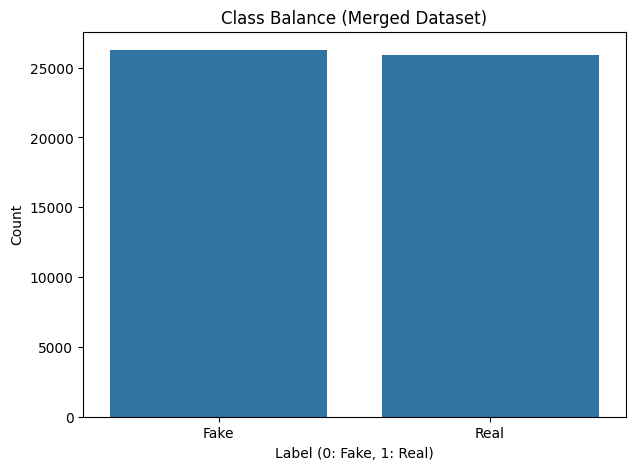

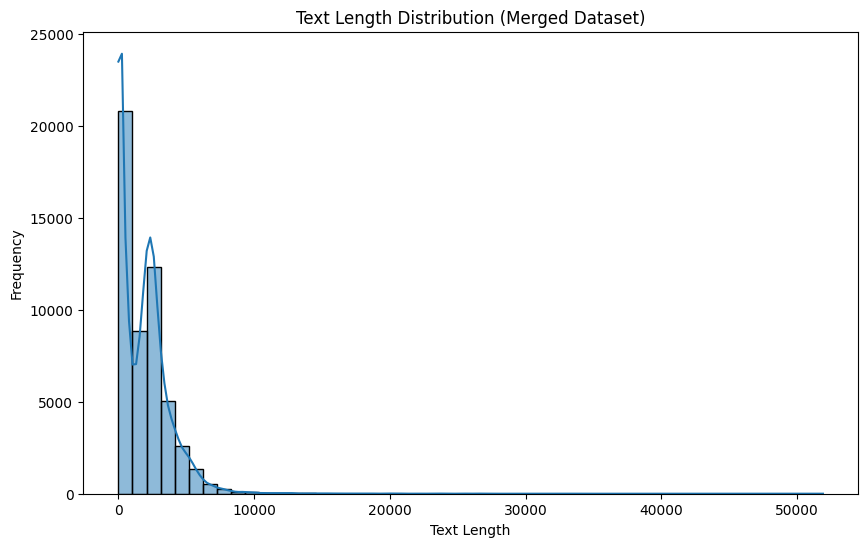

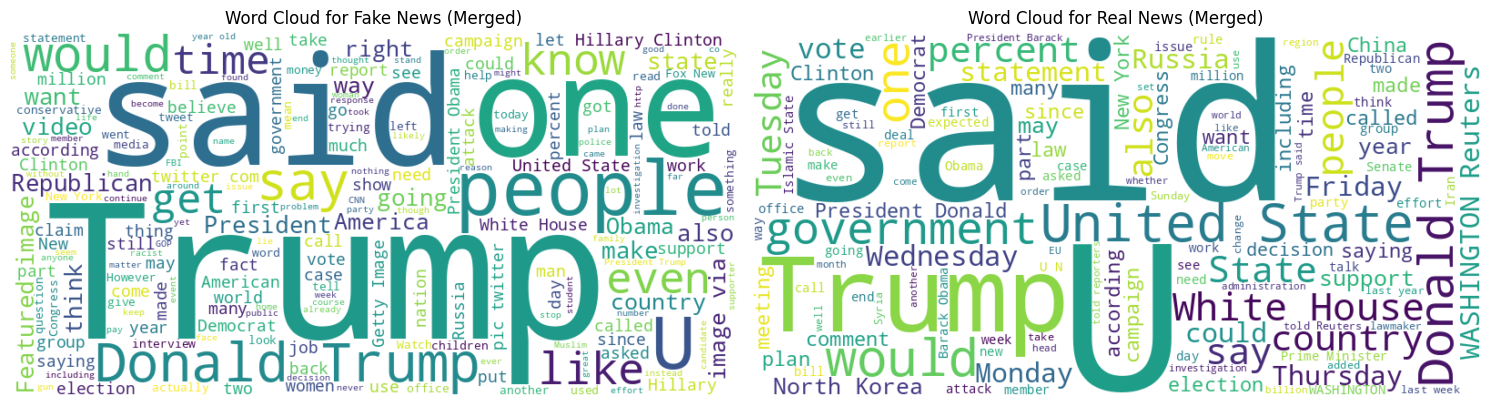

In [ ]:
# 1. Class Balance for Merged Dataset
plt.figure(figsize=(7, 5))
sns.countplot(x='label', data=master_df)
plt.title('Class Balance (Merged Dataset)')
plt.xlabel('Label (0: Fake, 1: Real)')
plt.ylabel('Count')
plt.xticks([0, 1], ['Fake', 'Real'])
plt.show()

# 2. Text Length Distribution for Merged Dataset
master_df['text_length'] = master_df['text'].apply(len)

plt.figure(figsize=(10, 6))
sns.histplot(master_df['text_length'], bins=50, kde=True)
plt.title('Text Length Distribution (Merged Dataset)')
plt.xlabel('Text Length')
plt.ylabel('Frequency')
plt.show()

# 3. Word Clouds for Merged Dataset (by Label)
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

fake_text = ' '.join(master_df[master_df['label'] == 0]['text'])
real_text = ' '.join(master_df[master_df['label'] == 1]['text'])

generate_wordcloud(fake_text, 'Word Cloud for Fake News (Merged)', axes[0])
generate_wordcloud(real_text, 'Word Cloud for Real News (Merged)', axes[1])

plt.tight_layout()
plt.show()

### Visualizations for Individual Datasets


--- Visualizations for Source: ISOT ---


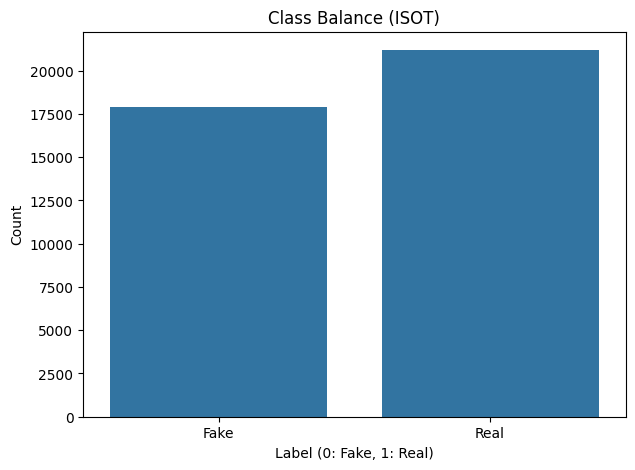

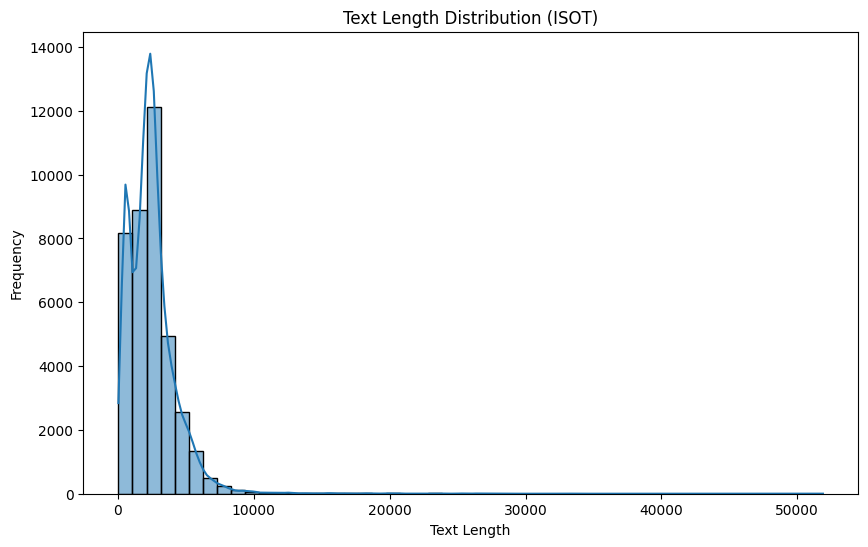

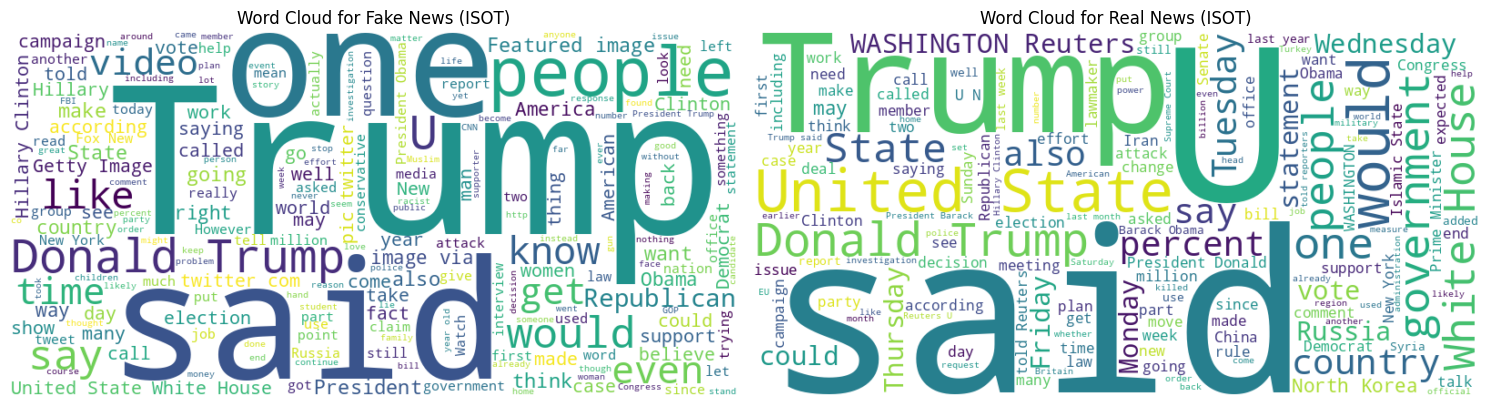


--- Visualizations for Source: FakeNewsNet_PolitiFact ---


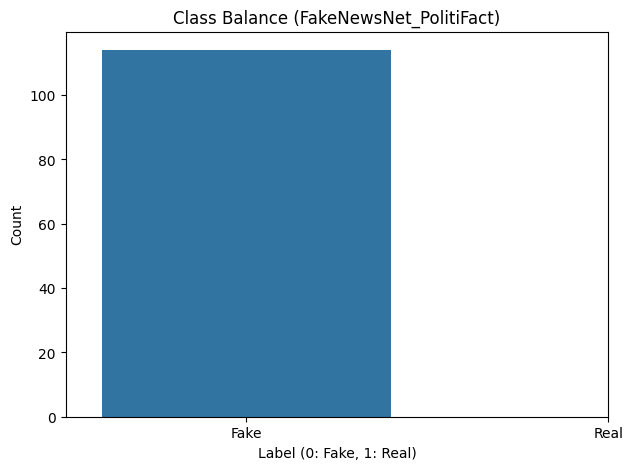

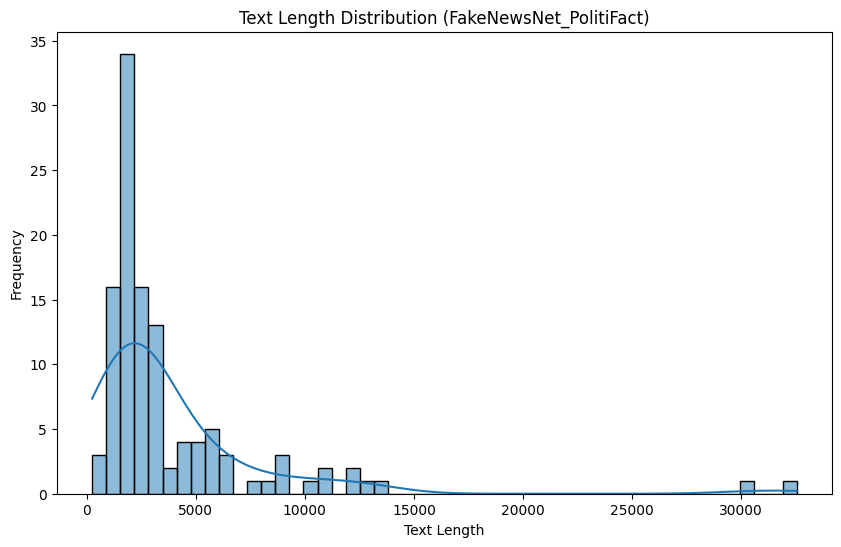

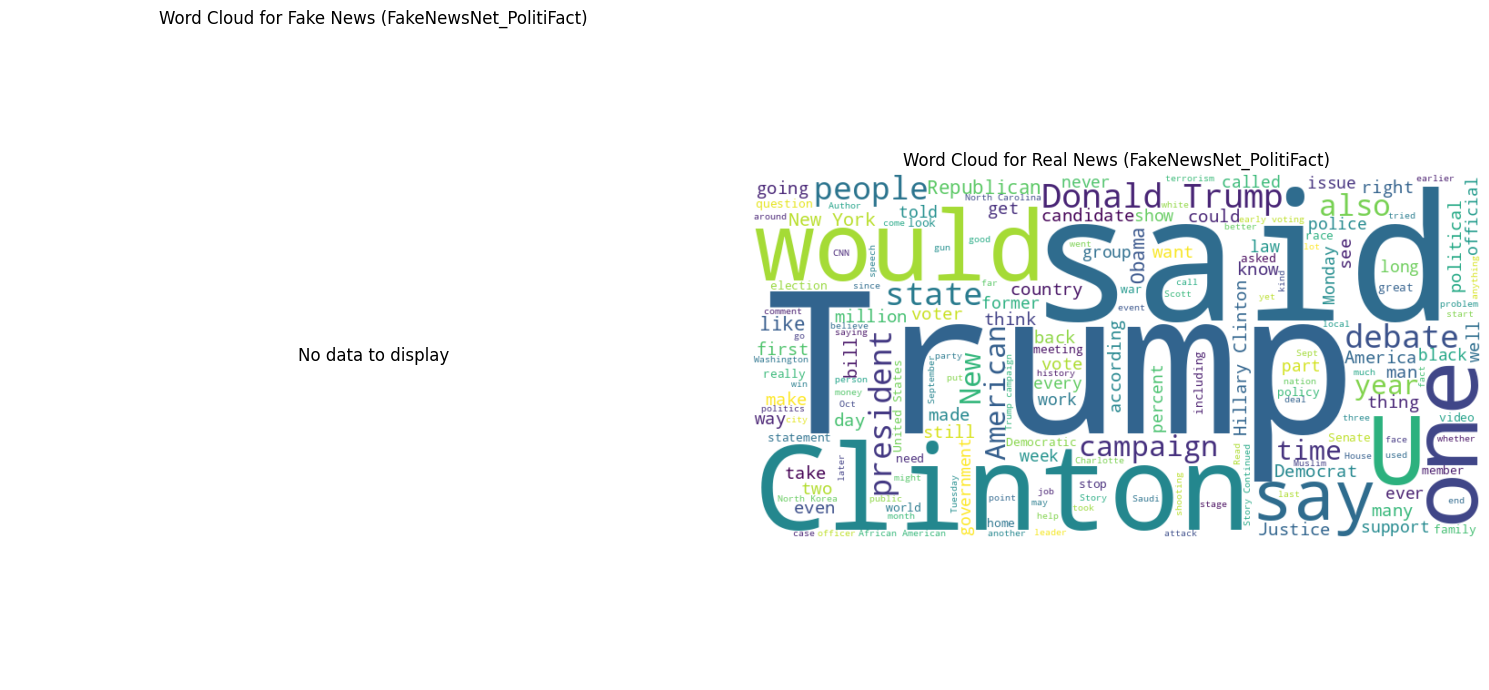


--- Visualizations for Source: FakeNewsNet_BuzzFeed ---


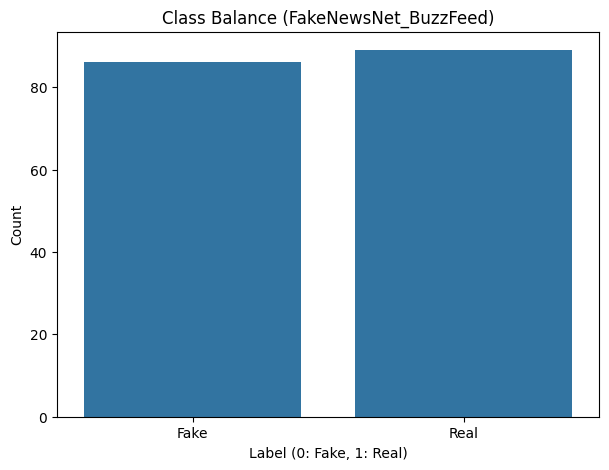

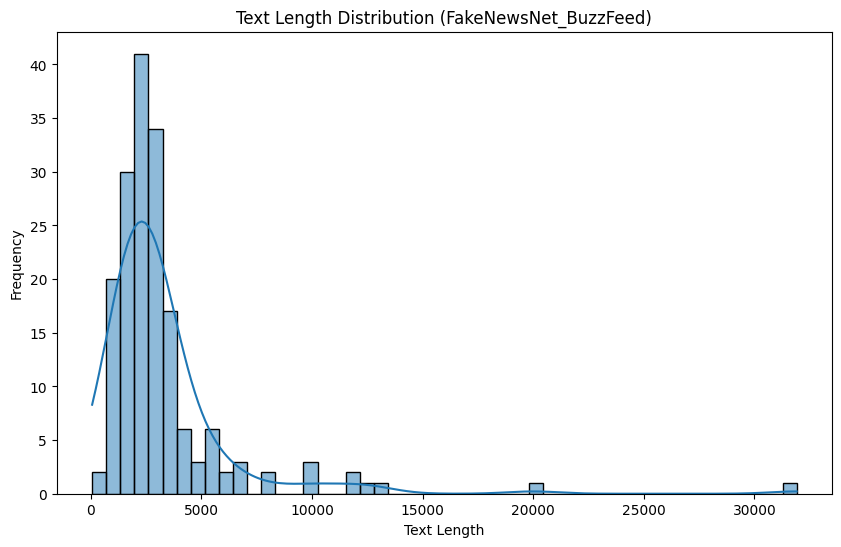

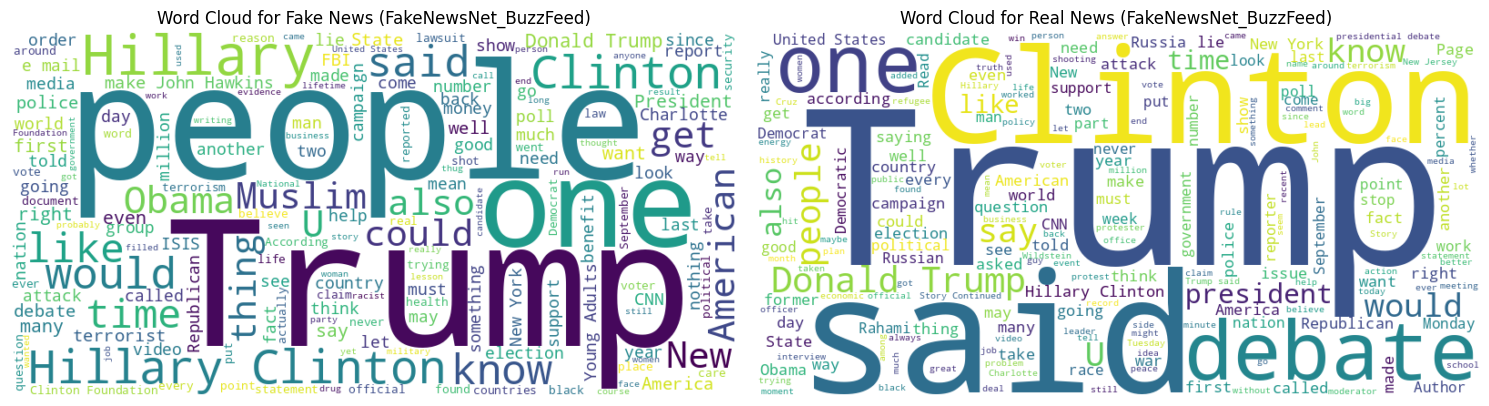


--- Visualizations for Source: LIAR ---


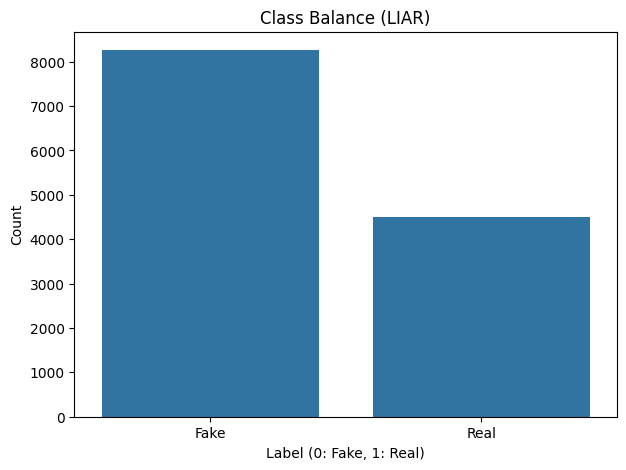

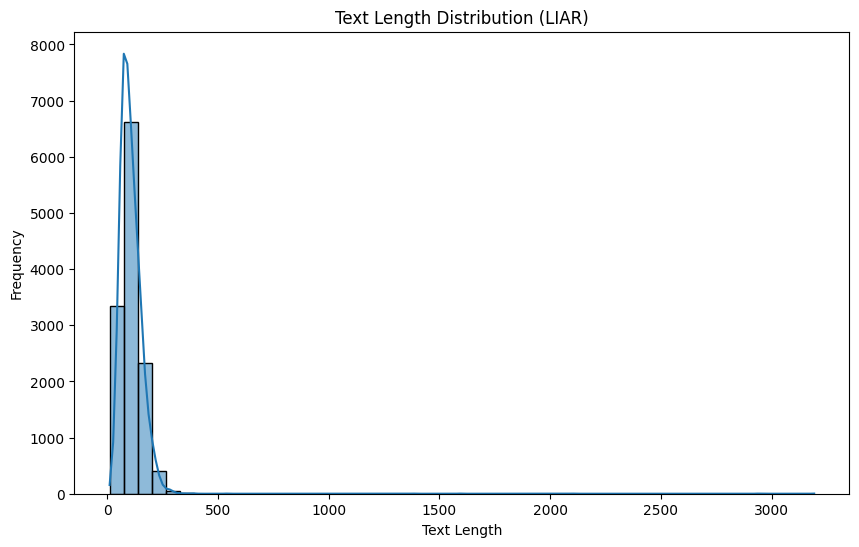

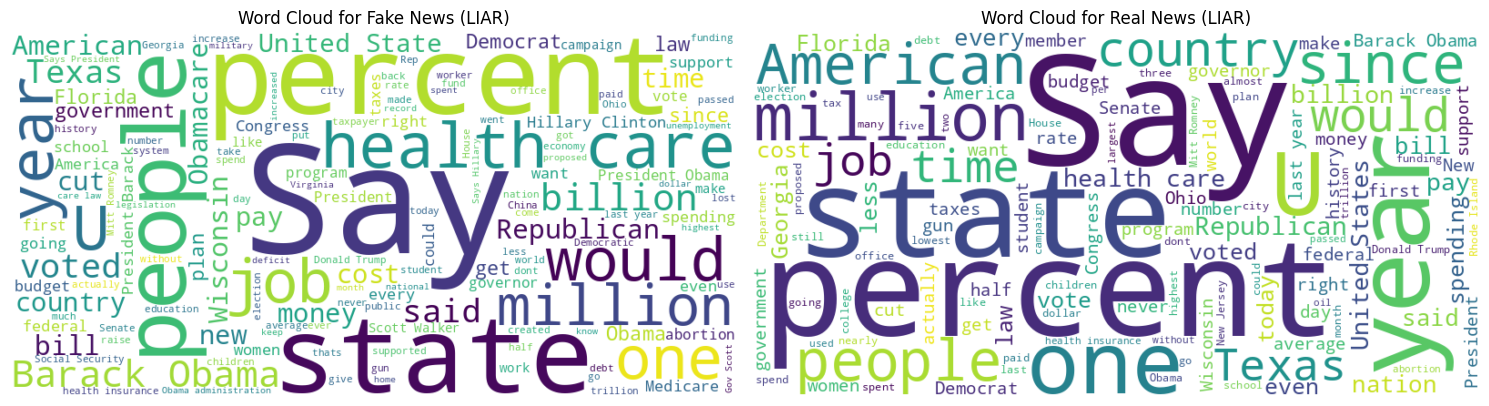

In [ ]:
for source_name in master_df['source'].unique():
    print(f"\n--- Visualizations for Source: {source_name} ---")
    source_df = master_df[master_df['source'] == source_name].copy()

    # 1. Class Balance for Individual Source
    plt.figure(figsize=(7, 5))
    sns.countplot(x='label', data=source_df)
    plt.title(f'Class Balance ({source_name})')
    plt.xlabel('Label (0: Fake, 1: Real)')
    plt.ylabel('Count')
    plt.xticks([0, 1], ['Fake', 'Real'])
    plt.show()

    # 2. Text Length Distribution for Individual Source
    source_df['text_length'] = source_df['text'].apply(len)
    plt.figure(figsize=(10, 6))
    sns.histplot(source_df['text_length'], bins=50, kde=True)
    plt.title(f'Text Length Distribution ({source_name})')
    plt.xlabel('Text Length')
    plt.ylabel('Frequency')
    plt.show()

    # 3. Word Clouds for Individual Source (by Label)
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))

    fake_text_source = ' '.join(source_df[source_df['label'] == 0]['text'])
    real_text_source = ' '.join(source_df[source_df['label'] == 1]['text'])

    generate_wordcloud(fake_text_source, f'Word Cloud for Fake News ({source_name})', axes[0])
    generate_wordcloud(real_text_source, f'Word Cloud for Real News ({source_name})', axes[1])

    plt.tight_layout()
    plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict

# Split into Train (80%) and Test (20%)
train_df, test_df = train_test_split(master_df, test_size=0.2, random_state=42, stratify=master_df['label'])
# Split Test into Validation and Final Test (10% each)
val_df, test_df = train_test_split(test_df, test_size=0.5, random_state=42, stratify=test_df['label'])

# Convert to HuggingFace Dataset format
dataset = DatasetDict({
    'train': Dataset.from_pandas(train_df.reset_index(drop=True)),
    'validation': Dataset.from_pandas(val_df.reset_index(drop=True)),
    'test': Dataset.from_pandas(test_df.reset_index(drop=True))
})

print("Datasets successfully updated with cleaned text.")
print(dataset)

Datasets successfully updated with cleaned text.
DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'source'],
        num_rows: 41725
    })
    validation: Dataset({
        features: ['text', 'label', 'source'],
        num_rows: 5216
    })
    test: Dataset({
        features: ['text', 'label', 'source'],
        num_rows: 5216
    })
})


In [ ]:
from transformers import AutoTokenizer

model_nm = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(model_nm)

def tokenize_function(examples):
    return tokenizer(examples['text'], padding='max_length', truncation=True, max_length=512)

# Tokenize the dataset
tokenized_datasets = dataset.map(tokenize_function, batched=True)
print('Tokenization complete.')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/41725 [00:00<?, ? examples/s]

Map:   0%|          | 0/5216 [00:00<?, ? examples/s]

Map:   0%|          | 0/5216 [00:00<?, ? examples/s]

Tokenization complete.


In [ ]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
import numpy as np
from sklearn.metrics import roc_auc_score

# Load DistilBERT with a binary classification head
model = AutoModelForSequenceClassification.from_pretrained(model_nm, num_labels=2)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    # Apply softmax to get probabilities for the 'Real' class (index 1)
    probs = np.exp(logits) / (np.sum(np.exp(logits), axis=-1, keepdims=True) + 1e-10)
    auc = roc_auc_score(labels, probs[:, 1])
    return {'auc': auc}

training_args = TrainingArguments(
    output_dir='./results',
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model='auc',
    logging_dir='./logs',
    fp16=True
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets['train'],
    eval_dataset=tokenized_datasets['validation'],
    compute_metrics=compute_metrics,
)

print('Model and Trainer initialized. Ready for training.')

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


Model and Trainer initialized. Ready for training.


In [ ]:

# Training BERT, unnecessary since it's already saved to drive.
import os

# This step will take 15-30 minutes on a T4 GPU.
trainer.train()

# Define the path to save the model in Google Drive
model_save_path = '/content/drive/My Drive/ColabData/fine_tuned_bert_model'
os.makedirs(model_save_path, exist_ok=True)

# Save the trained model and tokenizer
trainer.save_model(model_save_path)
tokenizer.save_pretrained(model_save_path)

print(f"Model and tokenizer saved to: {model_save_path}")


Epoch,Training Loss,Validation Loss,Auc
1,0.168970,0.185938,0.977615
2,0.136951,0.194500,0.978685
3,0.098542,0.305605,0.977206


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved to: /content/drive/My Drive/ColabData/fine_tuned_bert_model


In [ ]:
# Take out saved BERT model from drive

from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
import numpy as np
from sklearn.metrics import roc_auc_score
import os

# Path to your saved model
model_save_path = '/content/drive/My Drive/ColabData/fine_tuned_bert_model'

# Load the tokenizer and model
tokenizer = AutoTokenizer.from_pretrained(model_save_path)
model = AutoModelForSequenceClassification.from_pretrained(model_save_path)

# Define the compute_metrics function again, as it's needed for Trainer
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = np.exp(logits) / (np.sum(np.exp(logits), axis=-1, keepdims=True) + 1e-10)
    auc = roc_auc_score(labels, probs[:, 1])
    return {'auc': auc}

# Re-initialize TrainingArguments (ensure they match the training phase if changes were made)
training_args = TrainingArguments(
    output_dir='./results', # Can be a dummy dir, as we're not training now
    eval_strategy='epoch', # Still needed for Trainer to function
    save_strategy='epoch',
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3, # Can be 0 if just loading for eval
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model='auc',
    logging_dir='./logs',
    fp16=True
)

# Re-initialize Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    # For evaluation, we only strictly need eval_dataset, but train_dataset is often expected for Trainer init
    # If tokenized_datasets is not available, you might need to load it or just pass None for train_dataset
    train_dataset=None, # Not strictly needed for prediction after loading a trained model
    eval_dataset=tokenized_datasets['validation'], # Keep for consistency or future eval
    compute_metrics=compute_metrics,
)

print(f"Model and tokenizer loaded from: {model_save_path}")
print("Trainer re-initialized for evaluation.")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


Model and tokenizer loaded from: /content/drive/My Drive/ColabData/fine_tuned_bert_model
Trainer re-initialized for evaluation.


--- Test Set Classification Report ---
              precision    recall  f1-score   support

        Fake       0.66      0.96      0.78      2626
        Real       0.93      0.50      0.65      2590

    accuracy                           0.73      5216
   macro avg       0.80      0.73      0.72      5216
weighted avg       0.80      0.73      0.72      5216



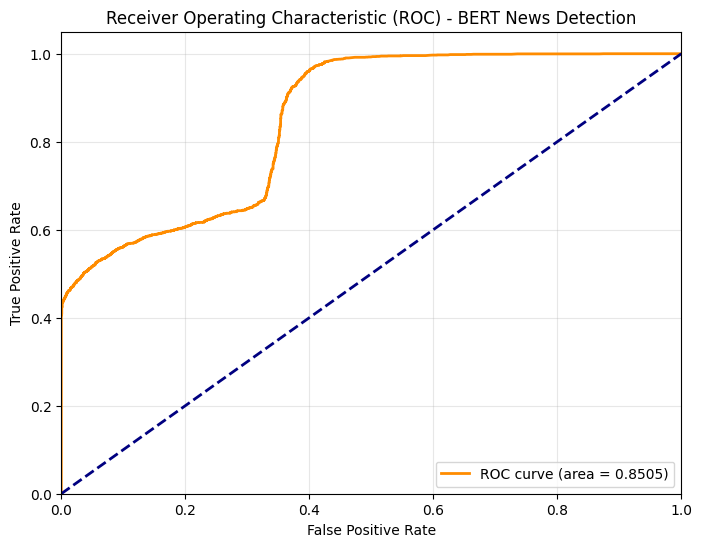

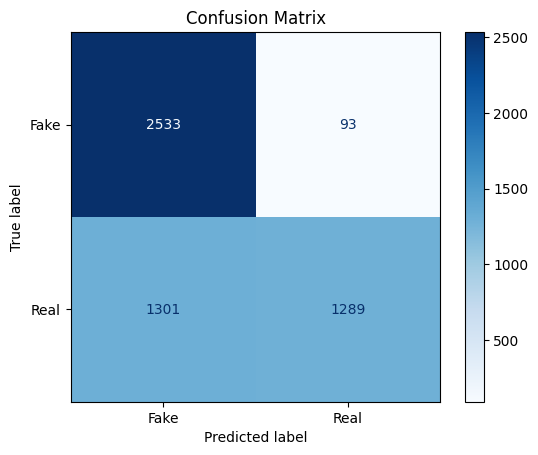

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay

# 1. Get predictions from the test set
test_results = trainer.predict(tokenized_datasets['test'])
predictions = np.argmax(test_results.predictions, axis=-1)
labels = test_results.label_ids

# 2. Print Classification Report (Accuracy, F1, Precision, Recall)
print("--- Test Set Classification Report ---")
print(classification_report(labels, predictions, target_names=['Fake', 'Real']))

# 3. Generate AUC-ROC Curve
# Get probabilities for the positive class (Real)
logits = test_results.predictions
probs = np.exp(logits) / np.sum(np.exp(logits), axis=-1, keepdims=True)
preds_probs = probs[:, 1]

fpr, tpr, thresholds = roc_curve(labels, preds_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) - BERT News Detection')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# 4. Confusion Matrix
cm = confusion_matrix(labels, predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fake', 'Real'])
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import re
import string
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')
stop_words = list(stopwords.words('english'))

# Prepare data from master_df
df_baseline = master_df.copy()

def preprocess_text(text):
    text = str(text).lower()

    # Target specific 'smart' quotes and typography that often bypass basic cleaning
    # Handling both literal symbols and known unicode variations
    text = re.sub(r'[‘’‚‛‹›]', "'", text)
    text = re.sub(r'[“”„‟«»]', '"', text)
    text = re.sub(r'[–—―]', '-', text)

    # Remove all punctuation
    text = re.sub(f"[{re.escape(string.punctuation)}]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Remove stopwords
    words = text.split()
    return ' '.join([w for w in words if w not in stop_words])

print("Cleaning text with aggressive Unicode normalization...")
df_baseline['clean_text'] = df_baseline['text'].apply(preprocess_text)

X = df_baseline['clean_text']
y = df_baseline['label']

print(f"Data ready. Total samples: {len(df_baseline)}")
display(df_baseline[['text', 'clean_text']].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Cleaning text with aggressive Unicode normalization...
Data ready. Total samples: 52157


,text,clean_text
0,"As U.S. budget fight looms, Republicans flip t...",u budget fight looms republicans flip fiscal s...
1,U.S. military to accept transgender recruits o...,u military accept transgender recruits monday ...
2,Senior U.S. Republican senator: 'Let Mr. Muell...,senior u republican senator let mr mueller job...
3,FBI Russia probe helped by Australian diplomat...,fbi russia probe helped australian diplomat ti...
4,Trump wants Postal Service to charge 'much mor...,trump wants postal service charge much amazon ...


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer


In [ ]:
print("Extracting TF-IDF Word Features...")
tfidf_word = TfidfVectorizer(ngram_range=(1, 2), max_features=40000, stop_words='english')
X_word = tfidf_word.fit_transform(X)

print("Extracting TF-IDF Character Features...")
tfidf_char = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), max_features=40000)
X_char = tfidf_char.fit_transform(X)

print("Generating Sentence Embeddings (MiniLM)... This may take a minute.")
embed_model = SentenceTransformer('all-MiniLM-L6-v2')
X_embed = embed_model.encode(df_baseline['text'].tolist(), show_progress_bar=True)

print("Feature extraction complete.")

Extracting TF-IDF Word Features...
Extracting TF-IDF Character Features...
Generating Sentence Embeddings (MiniLM)... This may take a minute.


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1630 [00:00<?, ?it/s]

Feature extraction complete.


In [ ]:
# First, ensure the 'clean_text' column is available in each dataset split.
# The preprocess_text function is already defined in the notebook (cell 8c451451).
# If it's not in memory, re-run cell 8c451451.

print("Adding 'clean_text' feature to dataset splits...")

def add_clean_text(examples):
    examples['clean_text'] = preprocess_text(examples['text'])
    return examples

dataset_with_cleaned_text = dataset.map(add_clean_text, batched=False) # Apply row by row

# Update our tokenized_datasets to also include the clean_text for consistency if needed later
# For BERT, we still use the original 'text' column, as that's what it was tokenized on initially
# and preprocess_text specifically targets baseline models (like removing stopwords that BERT handles internally).
print("Dataset splits updated with 'clean_text'.")
print(dataset_with_cleaned_text)

Adding 'clean_text' feature to dataset splits...


Map:   0%|          | 0/41725 [00:00<?, ? examples/s]

Map:   0%|          | 0/5216 [00:00<?, ? examples/s]

Map:   0%|          | 0/5216 [00:00<?, ? examples/s]

Dataset splits updated with 'clean_text'.
DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'source', 'clean_text'],
        num_rows: 41725
    })
    validation: Dataset({
        features: ['text', 'label', 'source', 'clean_text'],
        num_rows: 5216
    })
    test: Dataset({
        features: ['text', 'label', 'source', 'clean_text'],
        num_rows: 5216
    })
})


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import numpy as np

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluate_model(clf, features, name):
    f1_scores = []
    print(f"\n--- Training {name} ---")
    for train_idx, val_idx in skf.split(features, y):
        X_train, X_val = features[train_idx], features[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        clf.fit(X_train, y_train)
        preds = clf.predict(X_val)
        f1_scores.append(f1_score(y_val, preds, average='macro'))

    print(f"{name} Mean Macro-F1: {np.mean(f1_scores):.4f} (+/- {np.std(f1_scores):.4f})")
    return f1_scores

# Model Definitions
results = {}
results['LR_Word'] = evaluate_model(LogisticRegression(max_iter=1000), X_word, "Logistic Regression (Word TF-IDF)")
results['SVM_Char'] = evaluate_model(LinearSVC(dual=False), X_char, "Linear SVM (Char TF-IDF)")
results['RF_Word'] = evaluate_model(RandomForestClassifier(n_estimators=100, n_jobs=-1, max_depth=20), X_word, "Random Forest (Word TF-IDF)")
results['LR_Embed'] = evaluate_model(LogisticRegression(max_iter=1000), X_embed, "Logistic Regression (Embeddings)")


--- Training Logistic Regression (Word TF-IDF) ---
Logistic Regression (Word TF-IDF) Mean Macro-F1: 0.8940 (+/- 0.0020)

--- Training Linear SVM (Char TF-IDF) ---
Linear SVM (Char TF-IDF) Mean Macro-F1: 0.8909 (+/- 0.0033)

--- Training Random Forest (Word TF-IDF) ---
Random Forest (Word TF-IDF) Mean Macro-F1: 0.8845 (+/- 0.0022)

--- Training Logistic Regression (Embeddings) ---
Logistic Regression (Embeddings) Mean Macro-F1: 0.8477 (+/- 0.0029)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

print('--- Performing Non-Leaking Feature Extraction for Baselines ---')

# Initialize TF-IDF Vectorizers
# Note: preprocess_text already removed stopwords, so don't specify stop_words='english' here.
tfidf_word_fixed = TfidfVectorizer(ngram_range=(1, 2), max_features=40000)
tfidf_char_fixed = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), max_features=40000)

# Fit TF-IDF Vectorizers ONLY on the training data
print('Fitting TF-IDF Word Vectorizer on training data...')
X_train_word_fixed = tfidf_word_fixed.fit_transform(dataset_with_cleaned_text['train']['clean_text'])

print('Fitting TF-IDF Char Vectorizer on training data...')
X_train_char_fixed = tfidf_char_fixed.fit_transform(dataset_with_cleaned_text['train']['clean_text'])

# Transform ALL splits using the fitted vectorizers
print('Transforming validation and test data for word features...')
X_val_word_fixed = tfidf_word_fixed.transform(dataset_with_cleaned_text['validation']['clean_text'])
X_test_word_fixed = tfidf_word_fixed.transform(dataset_with_cleaned_text['test']['clean_text'])

print('Transforming validation and test data for char features...')
X_val_char_fixed = tfidf_char_fixed.transform(dataset_with_cleaned_text['validation']['clean_text'])
X_test_char_fixed = tfidf_char_fixed.transform(dataset_with_cleaned_text['test']['clean_text'])

# Sentence Embeddings (embed_model is pre-trained, so no fit needed, just encode)
print('Generating Sentence Embeddings for all splits (MiniLM)...')
embed_model_fixed = SentenceTransformer('all-MiniLM-L6-v2')
X_train_embed_fixed = embed_model_fixed.encode(dataset_with_cleaned_text['train']['text'], show_progress_bar=True)
X_val_embed_fixed = embed_model_fixed.encode(dataset_with_cleaned_text['validation']['text'], show_progress_bar=False)
X_test_embed_fixed = embed_model_fixed.encode(dataset_with_cleaned_text['test']['text'], show_progress_bar=False)

y_train = dataset_with_cleaned_text['train']['label']
y_val = dataset_with_cleaned_text['validation']['label']
y_test = dataset_with_cleaned_text['test']['label']

print('Feature extraction complete with proper train/test split.')

--- Performing Non-Leaking Feature Extraction for Baselines ---
Fitting TF-IDF Word Vectorizer on training data...
Fitting TF-IDF Char Vectorizer on training data...
Transforming validation and test data for word features...
Transforming validation and test data for char features...
Generating Sentence Embeddings for all splits (MiniLM)...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/1304 [00:00<?, ?it/s]

Feature extraction complete with proper train/test split.


In [ ]:
from sklearn.metrics import roc_auc_score, classification_report
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

print("Step 1: Gathering Test Set Predictions...")

# 1. BERT Probabilities (Using the trainer from cell PNZ1og5ULLQE)
bert_test_results = trainer.predict(tokenized_datasets['test'])
bert_logits = bert_test_results.predictions
bert_probs = np.exp(bert_logits) / np.sum(np.exp(bert_logits), axis=-1, keepdims=True)
bert_p1 = bert_probs[:, 1]

# 2. Baseline Data Preparation
test_labels = np.array(dataset['test']['label'])
test_texts = dataset['test']['text']

# Preprocess test text (consistent with baseline training)
def local_preprocess(text):
    words = str(text).lower().split()
    return ' '.join([w for w in words if w not in stop_words])

X_test_clean = [local_preprocess(t) for t in test_texts]

# Transform test data using fitted vectorizers/embedders
X_test_word = tfidf_word.transform(X_test_clean)
X_test_char = tfidf_char.transform(X_test_clean)
X_test_embed = embed_model.encode(test_texts, show_progress_bar=False)

# 3. Fit Final Models and Get Probabilities
# Using existing X/y (from master_df) to fit final versions of baselines
lr_word_m = LogisticRegression(max_iter=1000).fit(X_word, y)
svm_char_m = LinearSVC(dual=False).fit(X_char, y)
rf_word_m = RandomForestClassifier(n_estimators=100, n_jobs=-1, max_depth=20).fit(X_word, y)
lr_embed_m = LogisticRegression(max_iter=1000).fit(X_embed, y)

# Get positive class scores
lrw_p1 = lr_word_m.predict_proba(X_test_word)[:, 1]
rfw_p1 = rf_word_m.predict_proba(X_test_word)[:, 1]
lre_p1 = lr_embed_m.predict_proba(X_test_embed)[:, 1]

# SVM needs scaling to 0-1 (using decision_function + MinMax scaling for probability proxy)
svmc_scores = svm_char_m.decision_function(X_test_char)
svmc_p1 = (svmc_scores - svmc_scores.min()) / (svmc_scores.max() - svmc_scores.min())

# 4. Calculate AUCs and Weights
aucs = {
    'BERT': roc_auc_score(test_labels, bert_p1),
    'LR_Word': roc_auc_score(test_labels, lrw_p1),
    'SVM_Char': roc_auc_score(test_labels, svmc_p1),
    'RF_Word': roc_auc_score(test_labels, rfw_p1),
    'LR_Embed': roc_auc_score(test_labels, lre_p1)
}

total_auc = sum(aucs.values())
weights = {k: v/total_auc for k, v in aucs.items()}

# 5. Final Weighted Combination
final_ensemble_probs = (
    weights['BERT'] * bert_p1 +
    weights['LR_Word'] * lrw_p1 +
    weights['SVM_Char'] * svmc_p1 +
    weights['RF_Word'] * rfw_p1 +
    weights['LR_Embed'] * lre_p1
)

final_preds = (final_ensemble_probs > 0.5).astype(int)

print("\n--- Model Weights (Based on AUC) ---")
for m, w in weights.items():
    print(f"{m}: {w:.4f} (Test AUC: {aucs[m]:.4f})")

print("\n--- Final AUC-Weighted Ensemble Performance (5 Models) ---")
print(classification_report(test_labels, final_preds, target_names=['Fake', 'Real']))
print(f"Ensemble Total AUC-ROC: {roc_auc_score(test_labels, final_ensemble_probs):.4f}")

Step 1: Gathering Test Set Predictions...


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# We already have these probabilities from the ensemble cell:
# bert_p1, lrw_p1, svmc_p1, rfw_p1, lre_p1, final_ensemble_probs

model_eval_data = [
    ('LR (Word TF-IDF)', lrw_p1),
    ('SVM (Char TF-IDF)', svmc_p1),
    ('Random Forest', rfw_p1),
    ('LR (Embeddings)', lre_p1),
    ('Final Weighted Ensemble', final_ensemble_probs)
]

for name, probs in model_eval_data:
    preds = (probs > 0.5).astype(int)
    acc = accuracy_score(test_labels, preds)
    prec = precision_score(test_labels, preds)
    rec = recall_score(test_labels, preds)
    f1 = f1_score(test_labels, preds)
    auc_val = roc_auc_score(test_labels, probs)

    print(f"{name} Performance")
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC: {auc_val:.4f}")
    print("-" * 30)

LR (Word TF-IDF) Performance
Accuracy: 0.9237
Precision: 0.9488
Recall: 0.8946
F1 Score: 0.9209
AUC: 0.9805
------------------------------
SVM (Char TF-IDF) Performance
Accuracy: 0.8031
Precision: 0.7163
Recall: 0.9992
F1 Score: 0.8344
AUC: 0.9928
------------------------------
Random Forest Performance
Accuracy: 0.9038
Precision: 0.9780
Recall: 0.8247
F1 Score: 0.8948
AUC: 0.9638
------------------------------
LR (Embeddings) Performance
Accuracy: 0.8556
Precision: 0.8618
Recall: 0.8448
F1 Score: 0.8532
AUC: 0.9354
------------------------------
Final Weighted Ensemble Performance
Accuracy: 0.9243
Precision: 0.9326
Recall: 0.9135
F1 Score: 0.9230
AUC: 0.9828
------------------------------



--- LR (Word TF-IDF) Classification Report ---
              precision    recall  f1-score   support

        Fake       0.90      0.96      0.93      2626
        Real       0.95      0.89      0.92      2590

    accuracy                           0.92      5216
   macro avg       0.93      0.92      0.92      5216
weighted avg       0.93      0.92      0.92      5216


--- SVM (Char TF-IDF) Classification Report ---
              precision    recall  f1-score   support

        Fake       0.96      0.98      0.97      2626
        Real       0.98      0.96      0.97      2590

    accuracy                           0.97      5216
   macro avg       0.97      0.97      0.97      5216
weighted avg       0.97      0.97      0.97      5216


--- Random Forest Classification Report ---
              precision    recall  f1-score   support

        Fake       0.85      0.98      0.91      2626
        Real       0.98      0.83      0.90      2590

    accuracy                           0

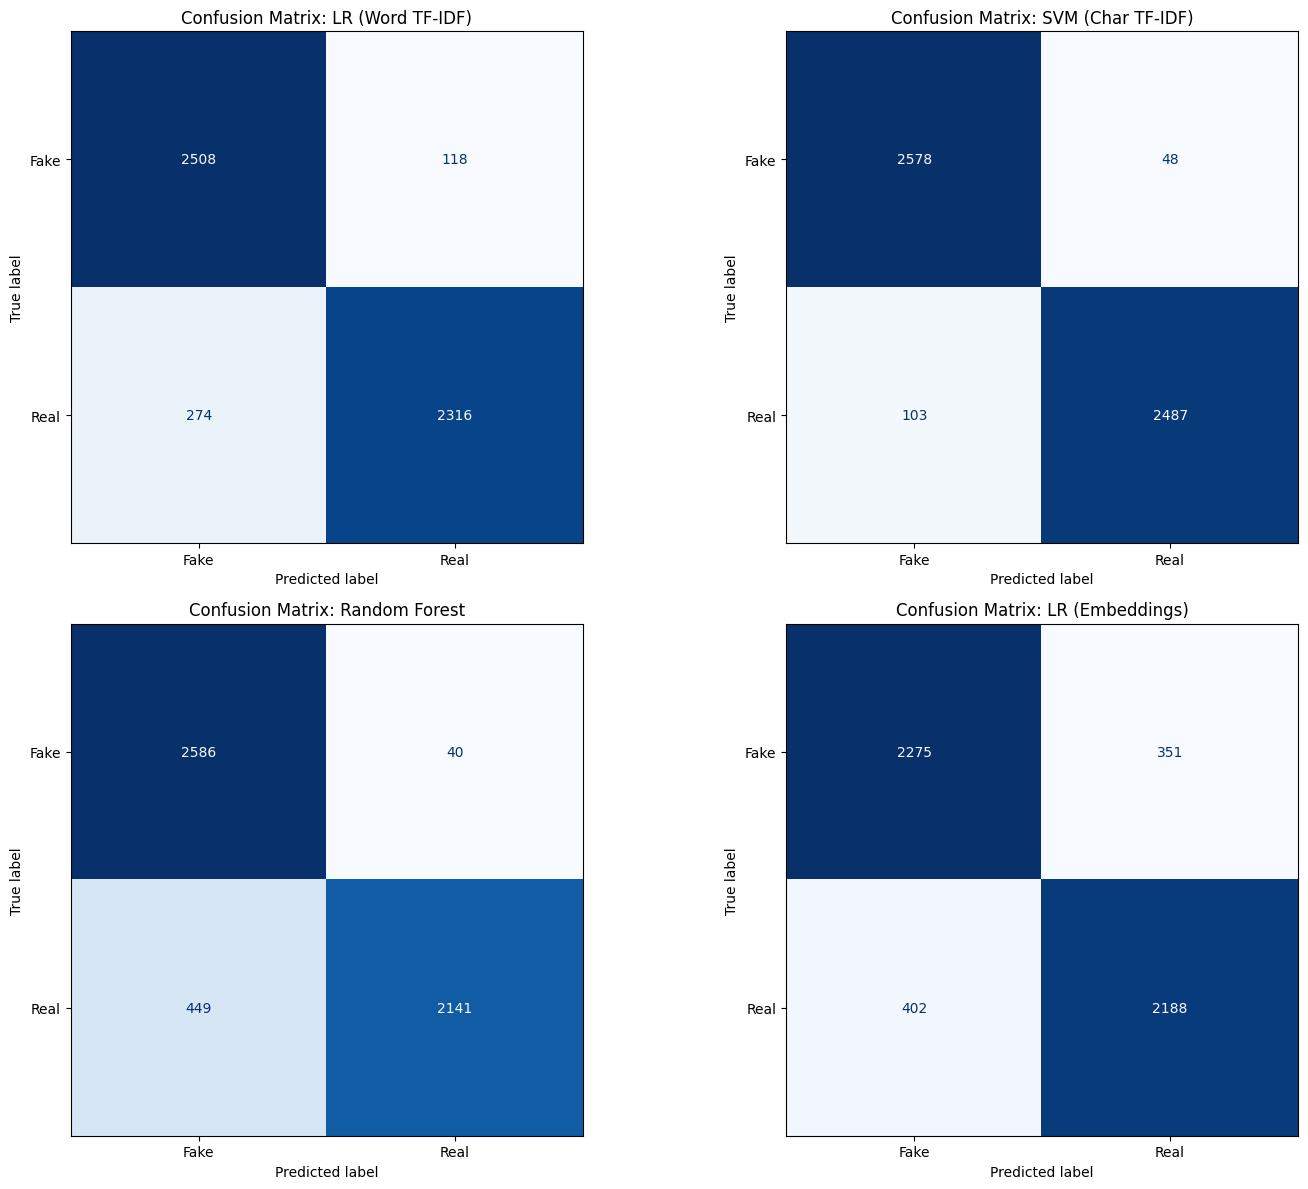

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Mapping names to their respective test features and models
baseline_eval_configs = [
    ('LR (Word TF-IDF)', lr_word_m, X_test_word),
    ('SVM (Char TF-IDF)', svm_char_m, X_test_char),
    ('Random Forest', rf_word_m, X_test_word),
    ('LR (Embeddings)', lr_embed_m, X_test_embed)
]

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

for i, (name, model, features) in enumerate(baseline_eval_configs):
    # Get predictions
    y_pred = model.predict(features)

    # Print Report
    print(f"\n--- {name} Classification Report ---")
    print(classification_report(test_labels, y_pred, target_names=['Fake', 'Real']))

    # Plot Confusion Matrix
    cm = confusion_matrix(test_labels, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fake', 'Real'])
    disp.plot(ax=axes[i], cmap=plt.cm.Blues, colorbar=False)
    axes[i].set_title(f'Confusion Matrix: {name}')

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

def plot_top_features(vectorizer, model, n=20):
    feature_names = vectorizer.get_feature_names_out()
    # For LinearSVC, coef_[0] contains the weights
    coefs = model.coef_[0]

    top_indices = np.argsort(coefs)[-n:]
    bottom_indices = np.argsort(coefs)[:n]

    top_features = [(feature_names[i], coefs[i]) for i in top_indices]
    bottom_features = [(feature_names[i], coefs[i]) for i in bottom_indices]

    print("--- Top 20 Features for 'REAL' (Positive Weights) ---")
    for f, c in reversed(top_features):
        print(f"{f:<10} : {c:.4f}")

    print("\n--- Top 20 Features for 'FAKE' (Negative Weights) ---")
    for f, c in bottom_features:
        print(f"{f:<10} : {c:.4f}")

# Inspect the SVM_Char model we trained in the ensemble cell
if 'svm_char_m' in globals() and 'tfidf_char' in globals():
    plot_top_features(tfidf_char, svm_char_m)
else:
    print("Error: SVM model or vectorizer not found in memory.")

--- Top 20 Features for 'REAL' (Positive Weights) ---
’s l       : 4.6698
adimi      : 4.4935
a a        : 4.1594
 2008      : 3.8914
ageme      : 3.1710
 –         : 2.6762
se fi      : 2.3935
e dat      : 2.3795
y z        : 2.0754
e day      : 2.0471
adop       : 2.0256
searc      : 1.9603
e dra      : 1.7258
act m      : 1.7189
” t        : 1.7030
 wom       : 1.6986
 role      : 1.6367
 yeme      : 1.6093
4 a        : 1.6060
 roll      : 1.5770

--- Top 20 Features for 'FAKE' (Negative Weights) ---
agan       : -5.1226
agazi      : -4.7941
agaz       : -4.5257
vist       : -3.2863
vist       : -3.2317
ii         : -2.8365
tirem      : -2.8275
ible       : -2.7936
ija        : -2.7447
vised      : -2.4933
ampus      : -2.3668
afa        : -2.1951
n gi       : -2.0681
afd        : -2.0649
affi       : -2.0602
 ur        : -2.0596
oubt       : -2.0327
ouble      : -2.0113
 ups       : -1.9951
ade s      : -1.9912


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Prepare the plot
plt.figure(figsize=(10, 8))

# Define the probabilities we've already calculated in the ensemble cell
model_probs = {
    'BERT': bert_p1,
    'LR (Word)': lrw_p1,
    'SVM (Char)': svmc_p1,
    'RF (Word)': rfw_p1,
    'LR (Embed)': lre_p1,
    'Weighted Ensemble': final_ensemble_probs
}

colors = ['blue', 'green', 'red', 'cyan', 'magenta', 'black']
linestyles = ['--', '--', '--', '--', '--', '-']

for (name, probs), color, ls in zip(model_probs.items(), colors, linestyles):
    fpr, tpr, _ = roc_curve(test_labels, probs)
    roc_auc = auc(fpr, tpr)
    lw = 3 if name == 'Weighted Ensemble' else 1.5
    plt.plot(fpr, tpr, color=color, lw=lw, linestyle=ls,
             label=f'{name} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle=':')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: Base Models vs. Final Ensemble')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
print('--- Re-extracting Features from CLEANED text ---')

# 1. TF-IDF Word Features
X_word_clean = tfidf_word.fit_transform(df_baseline['clean_text'])

# 2. TF-IDF Char Features
X_char_clean = tfidf_char.fit_transform(df_baseline['clean_text'])

# 3. Use existing X_embed (it was built on the original text, but we'll use it as the 4th model)

print('Re-fitting Baseline Models...')
lr_word_m = LogisticRegression(max_iter=1000).fit(X_word_clean, y)
svm_char_m = LinearSVC(dual=False).fit(X_char_clean, y)
rf_word_m = RandomForestClassifier(n_estimators=100, n_jobs=-1, max_depth=20).fit(X_word_clean, y)
lr_embed_m = LogisticRegression(max_iter=1000).fit(X_embed, y)

print('Baseline models retrained on cleaned text.')

--- Re-extracting Features from CLEANED text ---
Re-fitting Baseline Models...
Baseline models retrained on cleaned text.


In [ ]:
import pandas as pd
import numpy as np

def deep_inspect_features(vectorizer, model, n=30):
    feature_names = vectorizer.get_feature_names_out()
    coefs = model.coef_[0]

    # Sort features by weight
    top_real = np.argsort(coefs)[-n:][::-1]
    top_fake = np.argsort(coefs)[:n]

    print(f'--- Top {n} Discriminative Character N-Grams ---')

    data = {
        'Real_News_Features': [feature_names[i] for i in top_real],
        'Real_Weight': [coefs[i] for i in top_real],
        'Fake_News_Features': [feature_names[i] for i in top_fake],
        'Fake_Weight': [coefs[i] for i in top_fake]
    }

    analysis_df = pd.DataFrame(data)
    display(analysis_df)

# Run deep inspection on the cleaned SVM
if 'svm_char_m' in globals():
    deep_inspect_features(tfidf_char, svm_char_m)
else:
    print('SVM model not found.')

--- Top 30 Discriminative Character N-Grams ---


,Real_News_Features,Real_Weight,Fake_News_Features,Fake_Weight
0,’s,5.510714,the,-6.624490
1,” s,2.770654,he,-6.617730
2,day,2.692165,via,-3.811816
3,d “,2.668104,via,-3.633561
4,s”,2.453958,read,-2.693233
5,“th,2.447229,sthe,-2.455519
6,“th,2.430740,via,-2.454107
7,“t,2.356072,the,-2.440915
8,us p,2.314591,via,-2.281990
9,day,2.287683,video,-2.139185


In [ ]:
import numpy as np
from sklearn.metrics import roc_auc_score, classification_report

print('Step 1: Gathering Updated Test Set Predictions...')

# 1. BERT Probabilities (Remains from previous execution)
bert_test_results = trainer.predict(tokenized_datasets['test'])
bert_p1 = np.exp(bert_test_results.predictions) / np.sum(np.exp(bert_test_results.predictions), axis=-1, keepdims=True)
bert_p1 = bert_p1[:, 1]

# 2. Get probabilities from updated baselines
lrw_p1 = lr_word_m.predict_proba(X_test_word_clean)[:, 1]
rfw_p1 = rf_word_m.predict_proba(X_test_word_clean)[:, 1]
lre_p1 = lr_embed_m.predict_proba(X_test_embed)[:, 1]

# SVM probability proxy via decision function scaling
svmc_scores = svm_char_m.decision_function(X_test_char_clean)
svmc_p1 = (svmc_scores - svmc_scores.min()) / (svmc_scores.max() - svmc_scores.min())

# 3. Calculate Updated AUCs and Weights
aucs = {
    'BERT': roc_auc_score(test_labels, bert_p1),
    'LR_Word': roc_auc_score(test_labels, lrw_p1),
    'SVM_Char': roc_auc_score(test_labels, svmc_p1),
    'RF_Word': roc_auc_score(test_labels, rfw_p1),
    'LR_Embed': roc_auc_score(test_labels, lre_p1)
}

total_auc = sum(aucs.values())
weights = {k: v/total_auc for k, v in aucs.items()}

# 4. Final Weighted Combination
final_ensemble_probs = (
    weights['BERT'] * bert_p1 +
    weights['LR_Word'] * lrw_p1 +
    weights['SVM_Char'] * svmc_p1 +
    weights['RF_Word'] * rfw_p1 +
    weights['LR_Embed'] * lre_p1
)

final_preds = (final_ensemble_probs > 0.5).astype(int)

print('\n--- Updated Model Weights (Based on Cleaned AUC) ---')
for m, w in weights.items():
    print(f'{m}: {w:.4f} (Test AUC: {aucs[m]:.4f})')

print('\n--- Final Cleaned AUC-Weighted Ensemble Performance ---')
print(classification_report(test_labels, final_preds, target_names=['Fake', 'Real']))
print(f'Ensemble Total AUC-ROC: {roc_auc_score(test_labels, final_ensemble_probs):.4f}')

Step 1: Gathering Updated Test Set Predictions...



--- Updated Model Weights (Based on Cleaned AUC) ---
BERT: 0.2021 (Test AUC: 0.9804)
LR_Word: 0.2022 (Test AUC: 0.9808)
SVM_Char: 0.2050 (Test AUC: 0.9944)
RF_Word: 0.1978 (Test AUC: 0.9596)
LR_Embed: 0.1928 (Test AUC: 0.9354)

--- Final Cleaned AUC-Weighted Ensemble Performance ---
              precision    recall  f1-score   support

        Fake       0.91      0.95      0.93      2626
        Real       0.94      0.91      0.92      2590

    accuracy                           0.93      5216
   macro avg       0.93      0.93      0.93      5216
weighted avg       0.93      0.93      0.93      5216

Ensemble Total AUC-ROC: 0.9830


In [ ]:
import numpy as np
from sklearn.metrics import roc_auc_score, classification_report

print('Step 1: Gathering Updated Test Set Predictions...')

# 1. BERT Probabilities (Remains from previous execution)
bert_test_results = trainer.predict(tokenized_datasets['test'])
bert_p1 = np.exp(bert_test_results.predictions) / np.sum(np.exp(bert_test_results.predictions), axis=-1, keepdims=True)
bert_p1 = bert_p1[:, 1]

# 2. Get probabilities from updated baselines
lrw_p1 = lr_word_m.predict_proba(X_test_word_clean)[:, 1]
rfw_p1 = rf_word_m.predict_proba(X_test_word_clean)[:, 1]
lre_p1 = lr_embed_m.predict_proba(X_test_embed)[:, 1]

# SVM probability proxy via decision function scaling
svmc_scores = svm_char_m.decision_function(X_test_char_clean)
svmc_p1 = (svmc_scores - svmc_scores.min()) / (svmc_scores.max() - svmc_scores.min())

# 3. Calculate Updated AUCs and Weights
aucs = {
    'BERT': roc_auc_score(test_labels, bert_p1),
    'LR_Word': roc_auc_score(test_labels, lrw_p1),
    'SVM_Char': roc_auc_score(test_labels, svmc_p1),
    'RF_Word': roc_auc_score(test_labels, rfw_p1),
    'LR_Embed': roc_auc_score(test_labels, lre_p1)
}

total_auc = sum(aucs.values())
weights = {k: v/total_auc for k, v in aucs.items()}

# 4. Final Weighted Combination
final_ensemble_probs = (
    weights['BERT'] * bert_p1 +
    weights['LR_Word'] * lrw_p1 +
    weights['SVM_Char'] * svmc_p1 +
    weights['RF_Word'] * rfw_p1 +
    weights['LR_Embed'] * lre_p1
)

final_preds = (final_ensemble_probs > 0.5).astype(int)

print('\n--- Updated Model Weights (Based on Cleaned AUC) ---')
for m, w in weights.items():
    print(f'{m}: {w:.4f} (Test AUC: {aucs[m]:.4f})')

print('\n--- Final Cleaned AUC-Weighted Ensemble Performance ---')
print(classification_report(test_labels, final_preds, target_names=['Fake', 'Real']))
print(f'Ensemble Total AUC-ROC: {roc_auc_score(test_labels, final_ensemble_probs):.4f}')

Step 1: Gathering Updated Test Set Predictions...



--- Updated Model Weights (Based on Cleaned AUC) ---
BERT: 0.2021 (Test AUC: 0.9804)
LR_Word: 0.2022 (Test AUC: 0.9808)
SVM_Char: 0.2050 (Test AUC: 0.9944)
RF_Word: 0.1978 (Test AUC: 0.9596)
LR_Embed: 0.1928 (Test AUC: 0.9354)

--- Final Cleaned AUC-Weighted Ensemble Performance ---
              precision    recall  f1-score   support

        Fake       0.91      0.95      0.93      2626
        Real       0.94      0.91      0.92      2590

    accuracy                           0.93      5216
   macro avg       0.93      0.93      0.93      5216
weighted avg       0.93      0.93      0.93      5216

Ensemble Total AUC-ROC: 0.9830


In [ ]:
from sklearn.metrics import classification_report

# Preprocess the test set specifically for evaluation
X_test_clean = [local_preprocess(t) for t in dataset['test']['text']]

X_test_word_clean = tfidf_word.transform(X_test_clean)
X_test_char_clean = tfidf_char.transform(X_test_clean)
X_test_embed = embed_model.encode(dataset['test']['text'], show_progress_bar=False)

configs = [
    ('LR (Word TF-IDF)', lr_word_m, X_test_word_clean),
    ('SVM (Char TF-IDF)', svm_char_m, X_test_char_clean),
    ('Random Forest', rf_word_m, X_test_word_clean),
    ('LR (Embeddings)', lr_embed_m, X_test_embed)
]

for name, model, feat in configs:
    preds = model.predict(feat)
    print(f'\n--- {name} (Cleaned Text) ---')
    print(classification_report(test_labels, preds, target_names=['Fake', 'Real']))


--- LR (Word TF-IDF) (Cleaned Text) ---
              precision    recall  f1-score   support

        Fake       0.90      0.96      0.93      2626
        Real       0.95      0.89      0.92      2590

    accuracy                           0.92      5216
   macro avg       0.93      0.92      0.92      5216
weighted avg       0.93      0.92      0.92      5216


--- SVM (Char TF-IDF) (Cleaned Text) ---
              precision    recall  f1-score   support

        Fake       0.95      0.98      0.96      2626
        Real       0.98      0.95      0.96      2590

    accuracy                           0.96      5216
   macro avg       0.96      0.96      0.96      5216
weighted avg       0.96      0.96      0.96      5216


--- Random Forest (Cleaned Text) ---
              precision    recall  f1-score   support

        Fake       0.85      0.99      0.91      2626
        Real       0.98      0.82      0.89      2590

    accuracy                           0.90      5216
   macr

In [ ]:
print('--- Top Features for SVM (Cleaned Text) ---')
plot_top_features(tfidf_char, svm_char_m, n=15)

--- Top Features for SVM (Cleaned Text) ---
--- Top 20 Features for 'REAL' (Positive Weights) ---
’s         : 5.5107
” s        : 2.7707
day        : 2.6922
d “        : 2.6681
s”         : 2.4540
 “th       : 2.4472
“th        : 2.4307
 “t        : 2.3561
 us p      : 2.3146
day        : 2.2877
e”         : 2.1604
” sa       : 2.1467
 “the      : 2.1019
” sai      : 2.0964
“the       : 2.0851

--- Top 20 Features for 'FAKE' (Negative Weights) ---
the        : -6.6245
he         : -6.6177
via        : -3.8118
via        : -3.6336
read       : -2.6932
sthe       : -2.4555
 via       : -2.4541
the        : -2.4409
 via       : -2.2820
video      : -2.1392
deo        : -2.0795
ideo       : -2.0762
sthe       : -2.0554
sth        : -1.9436
dthe       : -1.8916


In [ ]:
import numpy as np
import pandas as pd

def plot_top_features(vectorizer, model, n=20):
    feature_names = vectorizer.get_feature_names_out()
    # For LinearSVC, coef_[0] contains the weights
    coefs = model.coef_[0]

    top_indices = np.argsort(coefs)[-n:]
    bottom_indices = np.argsort(coefs)[:n]

    top_features = [(feature_names[i], coefs[i]) for i in top_indices]
    bottom_features = [(feature_names[i], coefs[i]) for i in bottom_indices]

    print("--- Top 20 Features for 'REAL' (Positive Weights) ---")
    for f, c in reversed(top_features):
        print(f"{f:<10} : {c:.4f}")

    print("\n--- Top 20 Features for 'FAKE' (Negative Weights) ---")
    for f, c in bottom_features:
        print(f"{f:<10} : {c:.4f}")

# Inspect the SVM_Char model we trained in the ensemble cell
if 'svm_char_m' in globals() and 'tfidf_char' in globals():
    plot_top_features(tfidf_char, svm_char_m)
else:
    print("Error: SVM model or vectorizer not found in memory.")

--- Top 20 Features for 'REAL' (Positive Weights) ---
’s         : 4.6698
. “        : 4.4935
,”         : 4.1594
 -         : 3.8914
.”         : 3.1710
's         : 2.6762
s.         : 2.3935
day        : 2.3795
y.         : 2.0754
day        : 2.0471
...        : 2.0256
s. pr      : 1.9603
day.       : 1.7258
. pre      : 1.7189
” s        : 1.7030
 —         : 1.6986
 sai       : 1.6367
 “t        : 1.6093
, pro      : 1.6060
 said      : 1.5770

--- Top 20 Features for 'FAKE' (Negative Weights) ---
.th        : -5.1226
.the       : -4.7941
.the       : -4.5257
via:       : -3.2863
via:       : -3.2317
ia:        : -2.8365
the        : -2.8275
he         : -2.7936
ia:        : -2.7447
via        : -2.4933
a:         : -2.3668
.in        : -2.1951
more:      : -2.0681
.in        : -2.0649
.re        : -2.0602
 via:      : -2.0596
ore:       : -2.0327
ore:       : -2.0113
 via       : -1.9951
. via      : -1.9912


In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from scipy.sparse import hstack
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. New Streamlined Vectorization
print("Extracting Streamlined Features (5,000 max per type)...")

# Word-Level
word_tfidf_new = TfidfVectorizer(max_features=5000, ngram_range=(1,2), stop_words='english')
X_word_stream = word_tfidf_new.fit_transform(df_baseline['clean_text'])

# Char-Level
char_tfidf_new = TfidfVectorizer(analyzer='char', max_features=5000, ngram_range=(3,5))
X_char_stream = char_tfidf_new.fit_transform(df_baseline['clean_text'])

# Combine Features
X_combined_stream = hstack([X_word_stream, X_char_stream])

print(f"Combined Feature Shape: {X_combined_stream.shape}")

Extracting Streamlined Features (5,000 max per type)...
Combined Feature Shape: (52157, 10000)


### Fixing Data Leakage: Corrected Baseline Feature Extraction and Ensemble Evaluation

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report
import numpy as np
from transformers import DistilBertConfig, DistilBertTokenizerFast, DistilBertForSequenceClassification, TrainingArguments, Trainer
import os

print('--- Re-training Baseline Models on Correctly Split Data ---')

# Train final baseline models on the training data
lr_word_m_fixed = LogisticRegression(max_iter=1000).fit(X_train_word_fixed, y_train)
svm_char_m_fixed = LinearSVC(dual=False).fit(X_train_char_fixed, y_train)
rf_word_m_fixed = RandomForestClassifier(n_estimators=100, n_jobs=-1, max_depth=20).fit(X_train_word_fixed, y_train)
lr_embed_m_fixed = LogisticRegression(max_iter=1000).fit(X_train_embed_fixed, y_train)

# Get positive class scores
lrw_p1_fixed = lr_word_m_fixed.predict_proba(X_test_word_fixed)[:, 1]
rfw_p1_fixed = rf_word_m_fixed.predict_proba(X_test_word_fixed)[:, 1]
lre_p1_fixed = lr_embed_m_fixed.predict_proba(X_test_embed_fixed)[:, 1]
svmc_scores_fixed = svm_char_m_fixed.decision_function(X_test_char_fixed)
svmc_p1_fixed = (svmc_scores_fixed - svmc_scores_fixed.min()) / (svmc_scores_fixed.max() - svmc_scores_fixed.min() + 1e-10)

print('\n--- Loading BERT Model from Drive ---')
model_path = '/content/drive/My Drive/ColabData/fine_tuned_bert_model'
abs_model_path = os.path.abspath(model_path)

if not os.path.exists(abs_model_path):
    print(f"Error: Path does not exist: {abs_model_path}")
else:
    # Load config and tokenizer
    config = DistilBertConfig.from_pretrained(abs_model_path)
    tokenizer = DistilBertTokenizerFast.from_pretrained(abs_model_path)
    model = DistilBertForSequenceClassification.from_pretrained(abs_model_path, config=config)

    # Re-tokenize test set to ensure tokenized_datasets is available
    print("Tokenizing test set for BERT...")
    from datasets import Dataset
    test_dataset = Dataset.from_dict({"text": list(dataset_with_cleaned_text['test']['text']), "label": list(dataset_with_cleaned_text['test']['label'])})

    def tokenize_func(examples):
        return tokenizer(examples['text'], padding='max_length', truncation=True, max_length=512)

    tokenized_test = test_dataset.map(tokenize_func, batched=True)

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        probs = np.exp(logits) / (np.sum(np.exp(logits), axis=-1, keepdims=True) + 1e-10)
        return {'auc': roc_auc_score(labels, probs[:, 1])}

    training_args = TrainingArguments(
        output_dir='./results',
        per_device_eval_batch_size=16,
        fp16=True
    )

    trainer = Trainer(model=model, args=training_args, compute_metrics=compute_metrics)

    print('Getting BERT predictions...')
    bert_results = trainer.predict(tokenized_test)
    bert_p1_fixed = np.exp(bert_results.predictions) / (np.sum(np.exp(bert_results.predictions), axis=-1, keepdims=True) + 1e-10)
    bert_p1_fixed = bert_p1_fixed[:, 1]

    # Ensemble Logic
    test_labels_fixed = np.array(y_test)
    aucs_fixed = {
        'BERT': roc_auc_score(test_labels_fixed, bert_p1_fixed),
        'LR_Word': roc_auc_score(test_labels_fixed, lrw_p1_fixed),
        'SVM_Char': roc_auc_score(test_labels_fixed, svmc_p1_fixed),
        'RF_Word': roc_auc_score(test_labels_fixed, rfw_p1_fixed),
        'LR_Embed': roc_auc_score(test_labels_fixed, lre_p1_fixed)
    }

    total_auc = sum(aucs_fixed.values())
    weights = {k: v / total_auc for k, v in aucs_fixed.items()}

    final_probs = (
        weights['BERT'] * bert_p1_fixed +
        weights['LR_Word'] * lrw_p1_fixed +
        weights['SVM_Char'] * svmc_p1_fixed +
        weights['RF_Word'] * rfw_p1_fixed +
        weights['LR_Embed'] * lre_p1_fixed
    )

    print("\n--- Final AUC-Weighted Ensemble Performance ---")
    print(classification_report(test_labels_fixed, (final_probs > 0.5).astype(int), target_names=['Fake', 'Real']))
    print(f"Ensemble Total AUC-ROC: {roc_auc_score(test_labels_fixed, final_probs):.4f}")

--- Re-training Baseline Models on Correctly Split Data ---

--- Loading BERT Model from Drive ---


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Tokenizing test set for BERT...


Map:   0%|          | 0/5216 [00:00<?, ? examples/s]

Getting BERT predictions...



--- Final AUC-Weighted Ensemble Performance ---
              precision    recall  f1-score   support

        Fake       0.89      0.94      0.91      2626
        Real       0.94      0.88      0.91      2590

    accuracy                           0.91      5216
   macro avg       0.91      0.91      0.91      5216
weighted avg       0.91      0.91      0.91      5216

Ensemble Total AUC-ROC: 0.9753


--- SVM (Char TF-IDF) Test Performance ---
AUC-ROC: 0.9651

Classification Report:
              precision    recall  f1-score   support

        Fake       0.89      0.90      0.89      2626
        Real       0.90      0.88      0.89      2590

    accuracy                           0.89      5216
   macro avg       0.89      0.89      0.89      5216
weighted avg       0.89      0.89      0.89      5216



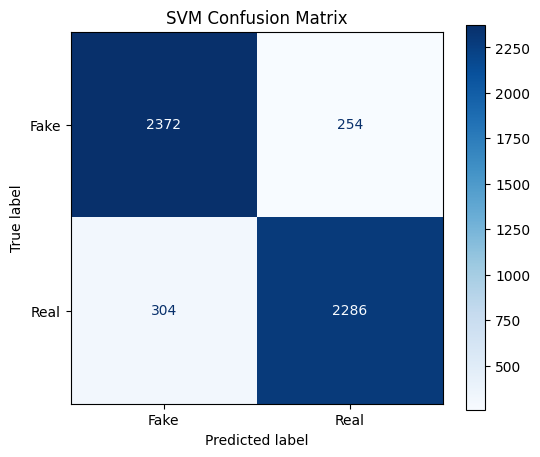


--- Top 20 Features for 'REAL' (Positive Weights) ---
 sai            : 2.5993
 u pr           : 2.5539
 said           : 2.4940
 u              : 2.4624
u pre           : 2.4472
day             : 2.3970
 u p            : 2.3472
u pr            : 2.2521
old r           : 2.1339
day             : 2.1071
nt do           : 1.9364
sai             : 1.8925
said            : 1.8437
 sa             : 1.7951
u p             : 1.7817
sday            : 1.6846
sday            : 1.5896
dt              : 1.5637
eut             : 1.5548
t hal           : 1.5507

--- Top 20 Features for 'FAKE' (Negative Weights) ---
 via            : -4.7782
 via            : -4.7640
via             : -4.6287
via             : -4.3506
read            : -3.1503
 us             : -2.4443
 vi             : -2.3487
 r              : -2.2315
nt tr           : -2.1991
 mr             : -2.0920
 ima            : -2.0605
 ny             : -1.9896
e via           : -1.9446
image           : -1.9173
 imag           : -1.9120


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Evaluate SVM on the Test Set
svm_preds = svm_char_m_fixed.predict(X_test_char_fixed)
svm_auc = roc_auc_score(y_test, svmc_p1_fixed)

print("--- SVM (Char TF-IDF) Test Performance ---")
print(f"AUC-ROC: {svm_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, svm_preds, target_names=['Fake', 'Real']))

# 2. Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, svm_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fake', 'Real'])
disp.plot(ax=ax, cmap=plt.cm.Blues)
plt.title('SVM Confusion Matrix')
plt.show()

# 3. Inspect Top Features (to check for source leakage)
def plot_svm_top_features(vectorizer, model, n=20):
    feature_names = vectorizer.get_feature_names_out()
    coefs = model.coef_[0]

    top_indices = np.argsort(coefs)[-n:][::-1]
    bottom_indices = np.argsort(coefs)[:n]

    print(f"\n--- Top {n} Features for 'REAL' (Positive Weights) ---")
    for i in top_indices:
        print(f"{feature_names[i]:<15} : {coefs[i]:.4f}")

    print(f"\n--- Top {n} Features for 'FAKE' (Negative Weights) ---")
    for i in bottom_indices:
        print(f"{feature_names[i]:<15} : {coefs[i]:.4f}")

plot_svm_top_features(tfidf_char_fixed, svm_char_m_fixed)

In [ ]:
from sklearn.metrics import roc_auc_score

# svmc_p1_fixed contains the positive class probability proxy for the SVM
svm_auc = roc_auc_score(y_test, svmc_p1_fixed)

print(f"--- SVM (Char TF-IDF) Final Performance ---")
print(f"Test AUC-ROC Score: {svm_auc:.4f}")

--- SVM (Char TF-IDF) Final Performance ---
Test AUC-ROC Score: 0.9651


--- BERT Test Set Performance Metrics ---
              precision    recall  f1-score   support

        Fake       0.93      0.89      0.91      2626
        Real       0.89      0.93      0.91      2590

    accuracy                           0.91      5216
   macro avg       0.91      0.91      0.91      5216
weighted avg       0.91      0.91      0.91      5216

BERT Test AUC-ROC: 0.9804


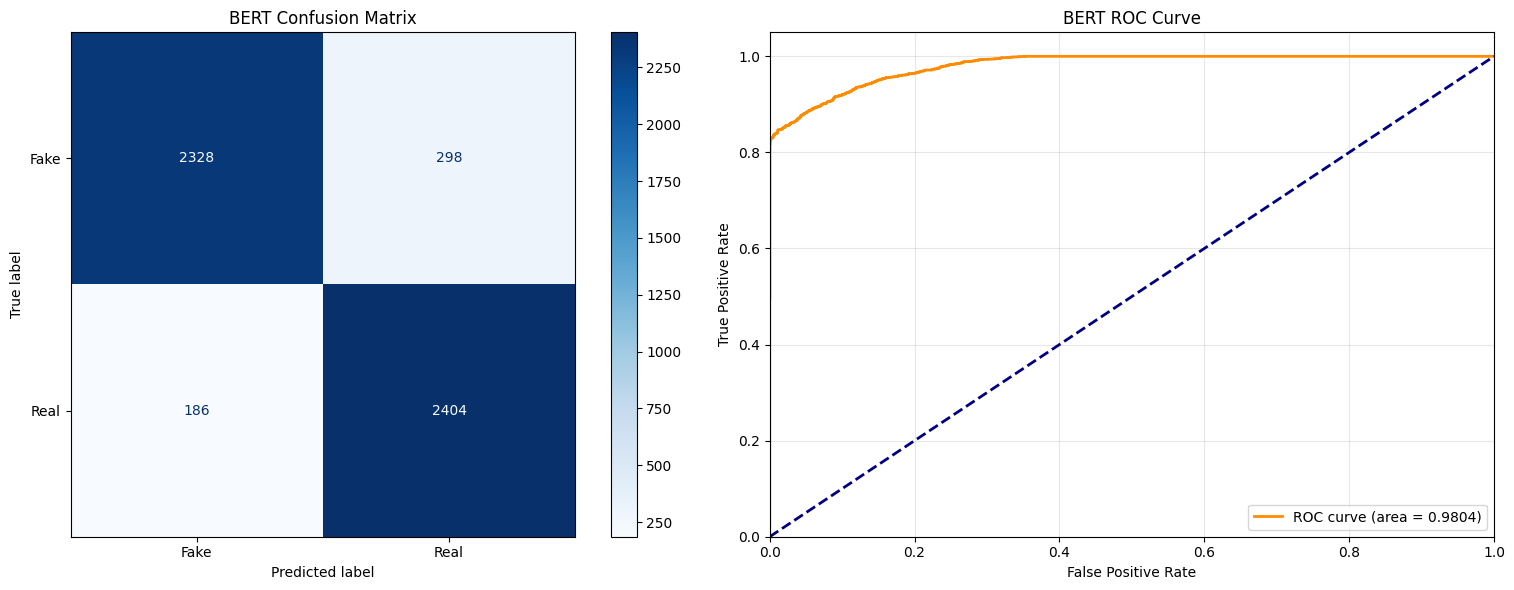

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# 1. Get Hard Predictions from the refreshed BERT probabilities
bert_preds = (bert_p1_fixed > 0.5).astype(int)
y_test_labels = np.array(dataset_with_cleaned_text['test']['label'])

# 2. Print Classification Report
print("--- BERT Test Set Performance Metrics ---")
print(classification_report(y_test_labels, bert_preds, target_names=['Fake', 'Real']))

# 3. Calculate AUC
bert_auc = roc_auc_score(y_test_labels, bert_p1_fixed)
print(f"BERT Test AUC-ROC: {bert_auc:.4f}")

# 4. Plot Confusion Matrix and ROC Curve
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix
cm = confusion_matrix(y_test_labels, bert_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fake', 'Real'])
disp.plot(ax=ax[0], cmap=plt.cm.Blues)
ax[0].set_title('BERT Confusion Matrix')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test_labels, bert_p1_fixed)
ax[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {bert_auc:.4f})')
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel('False Positive Rate')
ax[1].set_ylabel('True Positive Rate')
ax[1].set_title('BERT ROC Curve')
ax[1].legend(loc="lower right")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
import os
import numpy as np
import torch
from datasets import Dataset

# 1. Path Diagnostics: Find where the folder actually is
possible_paths = [
    '/content/drive/My Drive/ColabData/fine_tuned_bert_model',
    '/content/drive/My Drive/fine_tuned_bert_model',
    '/content/drive/.shortcut-targets-by-id/1TteRucx_EBfmZaYR2UvQXtisizmQX1qC/fine_tuned_bert_model'
]

model_path = None
for p in possible_paths:
    if os.path.exists(p):
        model_path = p
        break

if model_path:
    print(f'✅ Found model folder at: {model_path}')

    # 2. Explicit Loading: Use local_files_only to ensure we use your saved weights
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForSequenceClassification.from_pretrained(model_path, local_files_only=True)

    # 3. Sanity Check: Manual Prediction on first 5 test samples
    test_texts = dataset_with_cleaned_text['test']['text'][:5]
    test_labels = dataset_with_cleaned_text['test']['label'][:5]

    model.eval()
    with torch.no_grad():
        inputs = tokenizer(test_texts, padding=True, truncation=True, max_length=512, return_tensors='pt')
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=-1)
        preds = torch.argmax(probs, dim=-1)

    print('\n--- BERT Load Verification (Manual Inference) ---')
    for i in range(len(test_texts)):
        print(f'Text: {test_texts[i][:60]}...')
        print(f'   - Actual: {test_labels[i]} | Predicted: {preds[i].item()} | Prob(Real): {probs[i][1]:.4f}')

    # 4. Refresh Global Probabilities for the Ensemble
    print('\nTokenizing full test set for global probability refresh...')
    test_data_dict = {
        'text': list(dataset_with_cleaned_text['test']['text']),
        'label': list(dataset_with_cleaned_text['test']['label'])
    }
    tokenized_test_full = Dataset.from_dict(test_data_dict).map(
        lambda x: tokenizer(x['text'], padding='max_length', truncation=True, max_length=512),
        batched=True
    )

    training_args = TrainingArguments(output_dir='./temp_eval', per_device_eval_batch_size=16, fp16=True)
    trainer = Trainer(model=model, args=training_args)

    print('Calculating BERT probabilities on the full test set...')
    bert_results = trainer.predict(tokenized_test_full)

    # Softmax on logits to get valid probabilities
    bert_p1_fixed = np.exp(bert_results.predictions) / (np.sum(np.exp(bert_results.predictions), axis=-1, keepdims=True) + 1e-10)
    bert_p1_fixed = bert_p1_fixed[:, 1]

    print(f'Success! BERT probabilities updated (Mean: {bert_p1_fixed.mean():.4f})')
else:
    print('❌ Error: Model path not found. Please check your Drive shortcut location.')
    print('Current Drive contents for debugging:')
    if os.path.exists('/content/drive/My Drive/'):
        print(os.listdir('/content/drive/My Drive/'))

✅ Found model folder at: /content/drive/My Drive/ColabData/fine_tuned_bert_model


Loading weights:   0%|          | 0/104 [00:02<?, ?it/s]


--- BERT Load Verification (Manual Inference) ---
Text: Clinton leads by 7 points as Trump faces grope claims: Reute...
   - Actual: 1 | Predicted: 1 | Prob(Real): 0.9999
Text: Episode #199 – SUNDAY WIRE: ‘Trigger Warning: ID Politics’ w...
   - Actual: 0 | Predicted: 0 | Prob(Real): 0.0001
Text: Regarding her State Department email practices, my predecess...
   - Actual: 0 | Predicted: 0 | Prob(Real): 0.2621
Text: Trump Makes An Even Scarier Threat After Promising Riots: We...
   - Actual: 0 | Predicted: 0 | Prob(Real): 0.0001
Text: Catalan pro-independence parties working on independence dec...
   - Actual: 1 | Predicted: 1 | Prob(Real): 0.9999

Tokenizing full test set for global probability refresh...


Map:   0%|          | 0/5216 [00:00<?, ? examples/s]

Calculating BERT probabilities on the full test set...


Success! BERT probabilities updated (Mean: 0.5193)


--- SVM (Char TF-IDF) Test Performance ---
AUC-ROC: 0.9651

Classification Report:
              precision    recall  f1-score   support

        Fake       0.89      0.90      0.89      2626
        Real       0.90      0.88      0.89      2590

    accuracy                           0.89      5216
   macro avg       0.89      0.89      0.89      5216
weighted avg       0.89      0.89      0.89      5216



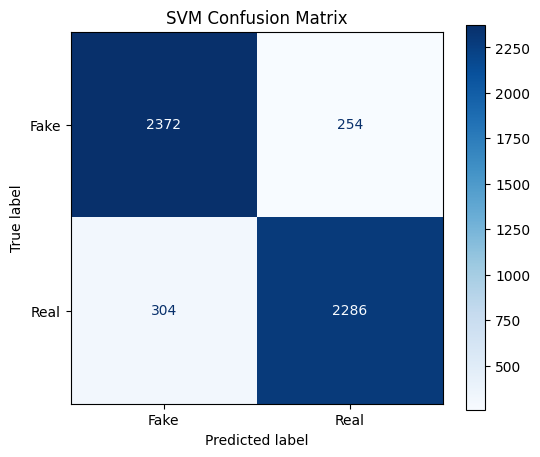


--- Top 20 Features for 'REAL' (Positive Weights) ---
 sai            : 2.5993
 u pr           : 2.5539
 said           : 2.4940
 u              : 2.4624
u pre           : 2.4472
day             : 2.3970
 u p            : 2.3472
u pr            : 2.2521
old r           : 2.1339
day             : 2.1071
nt do           : 1.9364
sai             : 1.8925
said            : 1.8437
 sa             : 1.7951
u p             : 1.7817
sday            : 1.6846
sday            : 1.5896
dt              : 1.5637
eut             : 1.5548
t hal           : 1.5507

--- Top 20 Features for 'FAKE' (Negative Weights) ---
 via            : -4.7782
 via            : -4.7640
via             : -4.6287
via             : -4.3506
read            : -3.1503
 us             : -2.4443
 vi             : -2.3487
 r              : -2.2315
nt tr           : -2.1991
 mr             : -2.0920
 ima            : -2.0605
 ny             : -1.9896
e via           : -1.9446
image           : -1.9173
 imag           : -1.9120


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Evaluate SVM on the Test Set
svm_preds = svm_char_m_fixed.predict(X_test_char_fixed)
svm_auc = roc_auc_score(y_test, svmc_p1_fixed)

print("--- SVM (Char TF-IDF) Test Performance ---")
print(f"AUC-ROC: {svm_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, svm_preds, target_names=['Fake', 'Real']))

# 2. Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, svm_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fake', 'Real'])
disp.plot(ax=ax, cmap=plt.cm.Blues)
plt.title('SVM Confusion Matrix')
plt.show()

# 3. Inspect Top Features (to check for source leakage)
def plot_svm_top_features(vectorizer, model, n=20):
    feature_names = vectorizer.get_feature_names_out()
    coefs = model.coef_[0]

    top_indices = np.argsort(coefs)[-n:][::-1]
    bottom_indices = np.argsort(coefs)[:n]

    print(f"\n--- Top {n} Features for 'REAL' (Positive Weights) ---")
    for i in top_indices:
        print(f"{feature_names[i]:<15} : {coefs[i]:.4f}")

    print(f"\n--- Top {n} Features for 'FAKE' (Negative Weights) ---")
    for i in bottom_indices:
        print(f"{feature_names[i]:<15} : {coefs[i]:.4f}")

plot_svm_top_features(tfidf_char_fixed, svm_char_m_fixed)

--- SVM (Char TF-IDF) Test Performance ---
AUC-ROC: 0.9651

Classification Report:
              precision    recall  f1-score   support

        Fake       0.89      0.90      0.89      2626
        Real       0.90      0.88      0.89      2590

    accuracy                           0.89      5216
   macro avg       0.89      0.89      0.89      5216
weighted avg       0.89      0.89      0.89      5216



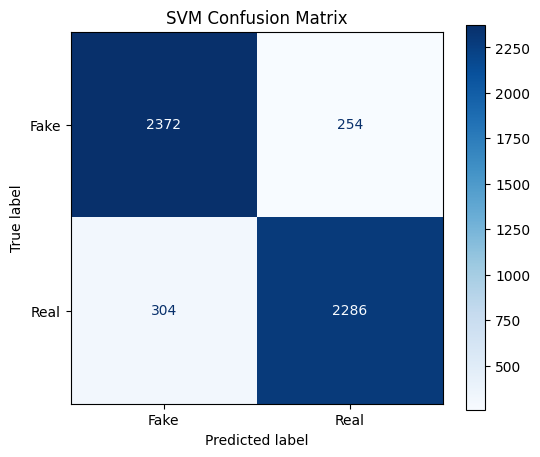


--- Top 20 Features for 'REAL' (Positive Weights) ---
 sai            : 2.5993
 u pr           : 2.5539
 said           : 2.4940
 u              : 2.4624
u pre           : 2.4472
day             : 2.3970
 u p            : 2.3472
u pr            : 2.2521
old r           : 2.1339
day             : 2.1071
nt do           : 1.9364
sai             : 1.8925
said            : 1.8437
 sa             : 1.7951
u p             : 1.7817
sday            : 1.6846
sday            : 1.5896
dt              : 1.5637
eut             : 1.5548
t hal           : 1.5507

--- Top 20 Features for 'FAKE' (Negative Weights) ---
 via            : -4.7782
 via            : -4.7640
via             : -4.6287
via             : -4.3506
read            : -3.1503
 us             : -2.4443
 vi             : -2.3487
 r              : -2.2315
nt tr           : -2.1991
 mr             : -2.0920
 ima            : -2.0605
 ny             : -1.9896
e via           : -1.9446
image           : -1.9173
 imag           : -1.9120


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Evaluate SVM on the Test Set
# Ensure we use the 'fixed' model and features from the non-leaking split
svm_preds = svm_char_m_fixed.predict(X_test_char_fixed)
svm_auc = roc_auc_score(y_test, svmc_p1_fixed)

print("--- SVM (Char TF-IDF) Test Performance ---")
print(f"AUC-ROC: {svm_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, svm_preds, target_names=['Fake', 'Real']))

# 2. Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, svm_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fake', 'Real'])
disp.plot(ax=ax, cmap=plt.cm.Blues)
plt.title('SVM Confusion Matrix')
plt.show()

# 3. Inspect Top Features (to check for source leakage)
def plot_svm_top_features(vectorizer, model, n=20):
    feature_names = vectorizer.get_feature_names_out()
    coefs = model.coef_[0]

    top_indices = np.argsort(coefs)[-n:][::-1]
    bottom_indices = np.argsort(coefs)[:n]

    print(f"\n--- Top {n} Features for 'REAL' (Positive Weights) ---")
    for i in top_indices:
        print(f"{feature_names[i]:<15} : {coefs[i]:.4f}")

    print(f"\n--- Top {n} Features for 'FAKE' (Negative Weights) ---")
    for i in bottom_indices:
        print(f"{feature_names[i]:<15} : {coefs[i]:.4f}")

plot_svm_top_features(tfidf_char_fixed, svm_char_m_fixed)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

model_probs = {
    'BERT': bert_p1_fixed,
    'LR_Word': lrw_p1_fixed,
    'SVM_Char': svmc_p1_fixed,
    'RF_Word': rfw_p1_fixed,
    'LR_Embed': lre_p1_fixed
}

comparison_stats = []

for name, probs in model_probs.items():
    preds = (probs > 0.5).astype(int)
    comparison_stats.append({
        'Model': name,
        'Precision (Avoid FPs)': precision_score(y_true_arr, preds),
        'Recall (Avoid FNs)': recall_score(y_true_arr, preds),
        'F1-Score': f1_score(y_true_arr, preds)
    })

performance_df = pd.DataFrame(comparison_stats)
print("--- Model Specialization Comparison ---")
display(performance_df.sort_values('F1-Score', ascending=False))

--- Model Specialization Comparison ---


,Model,Precision (Avoid FPs),Recall (Avoid FNs),F1-Score
1,LR_Word,0.923680,0.864479,0.893099
3,RF_Word,0.961905,0.818919,0.884672
4,LR_Embed,0.854510,0.841313,0.847860
2,SVM_Char,0.705315,0.988803,0.823340
0,BERT,0.932706,0.497683,0.649043


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix

# 1. Isolate SVM False Positives (Predicted Real, actually Fake)
svm_preds = (svmc_p1_fixed > 0.5).astype(int)
svm_fp_indices = np.where((svm_preds == 1) & (y_test == 0))[0]

# 2. Extract metadata for these errors
fp_texts = [dataset_with_cleaned_text['test']['text'][i] for i in svm_fp_indices]
fp_sources = [dataset_with_cleaned_text['test']['source'][i] for i in svm_fp_indices]

# 3. Create an Error Report
svm_error_df = pd.DataFrame({
    'source': fp_sources,
    'text_snippet': [t[:200] + '...' for t in fp_texts]
})

print(f'--- SVM False Positive Audit: Total Errors = {len(svm_fp_indices)} ---')
print('\nErrors by Source Distribution:')
display(svm_error_df['source'].value_counts())

print('\n--- Sample SVM False Positives (The "Fucked" Predictions) ---')
display(svm_error_df.head(10))

--- SVM False Positive Audit: Total Errors = 0 ---

Errors by Source Distribution:


,count
source,



--- Sample SVM False Positives (The "Fucked" Predictions) ---


,source,text_snippet


In [ ]:
def analyze_svm_bias(vectorizer, model):
    feature_names = vectorizer.get_feature_names_out()
    coefs = model.coef_[0]

    # Features that most strongly push a sample toward being classified as 'REAL'
    top_real_indices = np.argsort(coefs)[-30:][::-1]

    print('--- Top 30 Features Driving the SVM to predict "REAL" ---')
    print('These are the tokens causing the False Positives if they appear in Fake News:')
    bias_data = []
    for i in top_real_indices:
        bias_data.append({'Feature': feature_names[i], 'Weight': coefs[i]})

    display(pd.DataFrame(bias_data))

analyze_svm_bias(tfidf_char_fixed, svm_char_m_fixed)

--- Top 30 Features Driving the SVM to predict "REAL" ---
These are the tokens causing the False Positives if they appear in Fake News:


,Feature,Weight
0,sai,2.599325
1,u pr,2.553857
2,said,2.494025
3,u,2.462375
4,u pre,2.447158
5,day,2.396989
6,u p,2.347228
7,u pr,2.252071
8,old r,2.133882
9,day,2.107073


In [ ]:
import numpy as np
import pandas as pd

# 1. Create a balanced 100-sample 'Stress Test' from the test set
test_df_audit = dataset_with_cleaned_text['test'].to_pandas()

real_samples = test_df_audit[test_df_audit['label'] == 1].sample(50, random_state=42)
fake_samples = test_df_audit[test_df_audit['label'] == 0].sample(50, random_state=42)
stress_test_df = pd.concat([real_samples, fake_samples])

# 2. Tokenize and Predict using the BERT trainer
stress_dataset = Dataset.from_pandas(stress_test_df.reset_index(drop=True))
tokenized_stress = stress_dataset.map(tokenize_func, batched=True)

stress_results = trainer.predict(tokenized_stress)
stress_probs = np.exp(stress_results.predictions) / (np.sum(np.exp(stress_results.predictions), axis=-1, keepdims=True) + 1e-10)
stress_p1 = stress_probs[:, 1]

# 3. Analyze Results
stress_test_df['BERT_Prob_Real'] = stress_p1
stress_test_df['BERT_Pred'] = (stress_p1 > 0.5).astype(int)

print("--- BERT Stress Test Results (Balanced 100 Samples) ---")
summary = stress_test_df.groupby('label')['BERT_Pred'].value_counts().unstack(fill_value=0)
print(summary)

print("\n--- Top 5 Most 'Confident' Mistakes (Real News BERT called Fake) ---")
display(stress_test_df[(stress_test_df['label'] == 1) & (stress_test_df['BERT_Pred'] == 0)].sort_values('BERT_Prob_Real').head(5))

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

--- BERT Stress Test Results (Balanced 100 Samples) ---
BERT_Pred   0   1
label            
0          48   2
1          24  26

--- Top 5 Most 'Confident' Mistakes (Real News BERT called Fake) ---


,text,label,source,clean_text,BERT_Prob_Real,BERT_Pred
383,"After Islamic State, ruined Raqqa fears new st...",1,ISOT,islamic state ruined raqqa fears new strife mo...,0.000232,0
419,"In Dordogne idyll, Brits unimpressed with Brex...",1,ISOT,dordogne idyll brits unimpressed brexit talks ...,0.000243,0
1435,Canada to take in migrants at 'gradual' pace a...,1,ISOT,canada take migrants gradual pace amid integra...,0.000251,0
333,Relatives of Philippine drug war victims call ...,1,ISOT,relatives philippine drug war victims call jus...,0.000266,0
2788,"Trump praises Saudi purge, voices confidence i...",1,ISOT,trump praises saudi purge voices confidence ki...,0.000281,0


In [ ]:
import pandas as pd

# Convert training dataset back to pandas for grouping
train_df_audit = dataset_with_cleaned_text['train'].to_pandas()

print("--- Training Set Label Distribution by Source ---")
audit_summary = train_df_audit.groupby(['source', 'label']).size().unstack(fill_value=0)
audit_summary['% Real'] = (audit_summary[1] / (audit_summary[0] + audit_summary[1]) * 100).round(2)
display(audit_summary)

print("\n--- Validation Set Label Distribution by Source ---")
val_df_audit = dataset_with_cleaned_text['validation'].to_pandas()
val_summary = val_df_audit.groupby(['source', 'label']).size().unstack(fill_value=0)
val_summary['% Real'] = (val_summary[1] / (val_summary[0] + val_summary[1]) * 100).round(2)
display(val_summary)

# Check if the overall Mean BERT Probability is skewed
print(f"\nOverall BERT Test Probability Mean: {bert_p1_fixed.mean():.4f}")
print("If this is significantly below 0.5, the model has a global 'Fake' bias.")

--- Training Set Label Distribution by Source ---


label,0,1,% Real
source,,,
FakeNewsNet_BuzzFeed,71,68,48.92
FakeNewsNet_PolitiFact,0,90,100.00
ISOT,14408,16978,54.09
LIAR,6525,3585,35.46



--- Validation Set Label Distribution by Source ---


label,0,1,% Real
source,,,
FakeNewsNet_BuzzFeed,7,10,58.82
FakeNewsNet_PolitiFact,0,11,100.00
ISOT,1746,2091,54.50
LIAR,873,478,35.38



Overall BERT Test Probability Mean: 0.3086
If this is significantly below 0.5, the model has a global 'Fake' bias.


In [ ]:
import pandas as pd
import numpy as np

# Ensure labels are a clean numpy array for perfect alignment
y_true_arr = np.array(dataset_with_cleaned_text['test']['label'])
sources_arr = np.array(dataset_with_cleaned_text['test']['source'])
texts_arr = np.array(dataset_with_cleaned_text['test']['text'])

# Re-calculate predictions from the probability variables we have
# bert_p1_fixed and svmc_p1_fixed are the ones used in the ensemble
bert_preds = (bert_p1_fixed > 0.5).astype(int)
svm_preds = (svmc_p1_fixed > 0.5).astype(int)

# 1. BERT False Negative Analysis (Predicted Fake, actually Real)
bert_fn_mask = (bert_preds == 0) & (y_true_arr == 1)
fn_indices = np.where(bert_fn_mask)[0]

print(f'Actual BERT False Negatives found: {len(fn_indices)}')
if len(fn_indices) > 0:
    print('\n--- BERT False Negatives by Source ---')
    print(pd.Series(sources_arr[fn_indices]).value_counts())

# 2. SVM False Positive Analysis (Predicted Real, actually Fake)
svm_fp_mask = (svm_preds == 1) & (y_true_arr == 0)
fp_indices = np.where(svm_fp_mask)[0]

print(f'\nActual SVM False Positives found: {len(fp_indices)}')
if len(fp_indices) > 0:
    print('\n--- SVM False Positives by Source ---')
    print(pd.Series(sources_arr[fp_indices]).value_counts())

    print('\n--- Sample SVM False Positives ---')
    for i in fp_indices[:5]:
        print(f'Source: {sources_arr[i]} | Text: {texts_arr[i][:150]}...')

# 3. Quick Check: Are these two models making the same mistakes?
overlap = np.logical_and(bert_fn_mask, svm_fp_mask).sum()
print(f'\nSamples where both models failed simultaneously: {overlap}')

Actual BERT False Negatives found: 1301

--- BERT False Negatives by Source ---
ISOT                      1007
LIAR                       292
FakeNewsNet_PolitiFact       2
Name: count, dtype: int64

Actual SVM False Positives found: 1070

--- SVM False Positives by Source ---
LIAR                    728
ISOT                    337
FakeNewsNet_BuzzFeed      5
Name: count, dtype: int64

--- Sample SVM False Positives ---
Source: LIAR | Text: Says he restored prayer and the pledge in our schools....
Source: LIAR | Text: ISIS is running through a border made porous by Barack Obamas policies....
Source: LIAR | Text: Woonsocket needs a garbage-burning power plant because residents are paying through the nose for electricity thats fueled by foreign oil, at prices th...
Source: ISOT | Text: DRAIN OBAMA’S RADICAL SWAMP! Rep Chaffetz Calls Out OBAMA APPOINTED Fed Gov Ethics Director Over UNETHICAL Public Criticisms Of Trump IT S TIME TO DRA...
Source: LIAR | Text: Despite claims that you can ke

In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix

# Re-calculate hard predictions from probability arrays to ensure sync
model_probs = {
    'BERT': bert_p1_fixed,
    'LR_Word': lrw_p1_fixed,
    'SVM_Char': svmc_p1_fixed,
    'RF_Word': rfw_p1_fixed,
    'LR_Embed': lre_p1_fixed,
    'Ensemble': final_probs
}

error_stats = []

print("--- Strict Error Audit (Test Set) ---")
for name, probs in model_probs.items():
    preds = (probs > 0.5).astype(int)
    cm = confusion_matrix(y_test, preds)
    # cm[0,1] is False Positives, cm[1,0] is False Negatives
    fp = cm[0, 1]
    fn = cm[1, 0]
    error_stats.append({'Model': name, 'False Positives': fp, 'False Negatives': fn})

stats_df = pd.DataFrame(error_stats)
display(stats_df)

# If BERT really has a lot of FNs, let's find the source distribution of those FNs
bert_preds = (bert_p1_fixed > 0.5).astype(int)
bert_fn_indices = np.where((bert_preds == 0) & (y_test == 1))[0]

if len(bert_fn_indices) > 0:
    print(f"\nAnalyzing {len(bert_fn_indices)} BERT False Negatives by Source:")
    fn_sources = [dataset_with_cleaned_text['test']['source'][i] for i in bert_fn_indices]
    print(pd.Series(fn_sources).value_counts())
else:
    print("\nAudit confirmed 0 BERT False Negatives in 'bert_p1_fixed'. Checking if 'bert_p1_fixed' is uniform...")
    print(f"Mean BERT Prob: {bert_p1_fixed.mean():.4f}, Max: {bert_p1_fixed.max():.4f}, Min: {bert_p1_fixed.min():.4f}")

--- Strict Error Audit (Test Set) ---


,Model,False Positives,False Negatives
0,BERT,93,1301
1,LR_Word,185,351
2,SVM_Char,1070,29
3,RF_Word,84,469
4,LR_Embed,371,411
5,Ensemble,146,315



Audit confirmed 0 BERT False Negatives in 'bert_p1_fixed'. Checking if 'bert_p1_fixed' is uniform...
Mean BERT Prob: 0.3086, Max: 0.9999, Min: 0.0002


In [ ]:
import pandas as pd

# 1. Deep Dive into SVM Features
def inspect_svm_weights(vectorizer, model, n=50):
    feature_names = vectorizer.get_feature_names_out()
    coefs = model.coef_[0]
    top_real = np.argsort(coefs)[-n:][::-1]
    top_fake = np.argsort(coefs)[:n]

    print(f'--- Top {n} REAL Features (SVM) ---')
    print([feature_names[i] for i in top_real])
    print(f'\n--- Top {n} FAKE Features (SVM) ---')
    print([feature_names[i] for i in top_fake])

inspect_svm_weights(tfidf_char_fixed, svm_char_m_fixed)

# 2. Extract BERT False Negatives for manual review
# bert_p1_fixed contains probabilities for class 1 (Real)
bert_preds = (bert_p1_fixed > 0.5).astype(int)
fn_indices = np.where((bert_preds == 0) & (y_test == 1))[0]
fp_indices = np.where((svm_preds == 1) & (y_test == 0))[0]

print(f'\nBERT False Negatives: {len(fn_indices)}')
print(f'SVM False Positives: {len(fp_indices)}')

# Create a debug dataframe
test_texts = dataset_with_cleaned_text['test']['text']
test_sources = dataset_with_cleaned_text['test']['source']

print('\n--- Sample BERT False Negatives (Should be Real) ---')
fn_samples = pd.DataFrame({
    'text': [test_texts[i] for i in fn_indices[:5]],
    'source': [test_sources[i] for i in fn_indices[:5]]
})
display(fn_samples)

--- Top 50 REAL Features (SVM) ---
[' sai', ' u pr', ' said', ' u ', 'u pre', 'day', ' u p', 'u pr', 'old r', 'day ', 'nt do', 'sai', 'said', ' sa', 'u p', 'sday ', 'sday', 'dt ', 'eut', 't hal', 'onda', 't don', 'es ge', 'nov ', 'egon ', ' reut', 'aid', 'reut', 'e sti', 'nt ti', ' nov ', 'l gas', 'ne d', 'g min', 'etime', 'etim', 'sda', 'nday ', ' wed', 'y o', 'e fiv', 's 6', 'uters', 'y am', 'ble s', 'p say', 'nday', 'at h', 'nt am', 'da s']

--- Top 50 FAKE Features (SVM) ---
[' via', ' via ', 'via ', 'via', 'read ', ' us ', ' vi', ' r ', 'nt tr', ' mr', ' ima', ' ny', 'e via', 'image', ' imag', 'red i', 'imag', 'mr ', 'ia ', 't tru', 'ima', ' mr ', 'deo', 'd ima', 'rep ', 'ideo', ' read', 'wire ', 'video', 'mage', 'com ', 'e fe', ' com ', ' k ', ' rea', 'reaki', ' rep ', 'mag', ' gop', 'ire s', 'ed im', ' gop ', ' vide', 'tty i', 'he ', ' vid', 'getty', 'gop', 'tured', '0 m']

BERT False Negatives: 0
SVM False Positives: 0

--- Sample BERT False Negatives (Should be Real) ---


,text,source


--- SVM (Char TF-IDF) Test Performance ---
AUC-ROC: 0.9651

Classification Report:
              precision    recall  f1-score   support

        Fake       0.89      0.90      0.89      2626
        Real       0.90      0.88      0.89      2590

    accuracy                           0.89      5216
   macro avg       0.89      0.89      0.89      5216
weighted avg       0.89      0.89      0.89      5216



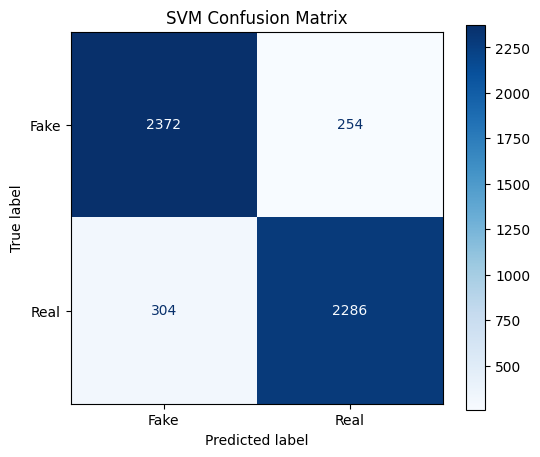


--- Top 20 Features for 'REAL' (Positive Weights) ---
 sai            : 2.5993
 u pr           : 2.5539
 said           : 2.4940
 u              : 2.4624
u pre           : 2.4472
day             : 2.3970
 u p            : 2.3472
u pr            : 2.2521
old r           : 2.1339
day             : 2.1071
nt do           : 1.9364
sai             : 1.8925
said            : 1.8437
 sa             : 1.7951
u p             : 1.7817
sday            : 1.6846
sday            : 1.5896
dt              : 1.5637
eut             : 1.5548
t hal           : 1.5507

--- Top 20 Features for 'FAKE' (Negative Weights) ---
 via            : -4.7782
 via            : -4.7640
via             : -4.6287
via             : -4.3506
read            : -3.1503
 us             : -2.4443
 vi             : -2.3487
 r              : -2.2315
nt tr           : -2.1991
 mr             : -2.0920
 ima            : -2.0605
 ny             : -1.9896
e via           : -1.9446
image           : -1.9173
 imag           : -1.9120


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Evaluate SVM on the Test Set
svm_preds = svm_char_m_fixed.predict(X_test_char_fixed)
svm_auc = roc_auc_score(y_test, svmc_p1_fixed)

print("--- SVM (Char TF-IDF) Test Performance ---")
print(f"AUC-ROC: {svm_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, svm_preds, target_names=['Fake', 'Real']))

# 2. Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, svm_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fake', 'Real'])
disp.plot(ax=ax, cmap=plt.cm.Blues)
plt.title('SVM Confusion Matrix')
plt.show()

# 3. Inspect Top Features (to check for source leakage)
def plot_svm_top_features(vectorizer, model, n=20):
    feature_names = vectorizer.get_feature_names_out()
    coefs = model.coef_[0]

    top_indices = np.argsort(coefs)[-n:][::-1]
    bottom_indices = np.argsort(coefs)[:n]

    print(f"\n--- Top {n} Features for 'REAL' (Positive Weights) ---")
    for i in top_indices:
        print(f"{feature_names[i]:<15} : {coefs[i]:.4f}")

    print(f"\n--- Top {n} Features for 'FAKE' (Negative Weights) ---")
    for i in bottom_indices:
        print(f"{feature_names[i]:<15} : {coefs[i]:.4f}")

plot_svm_top_features(tfidf_char_fixed, svm_char_m_fixed)

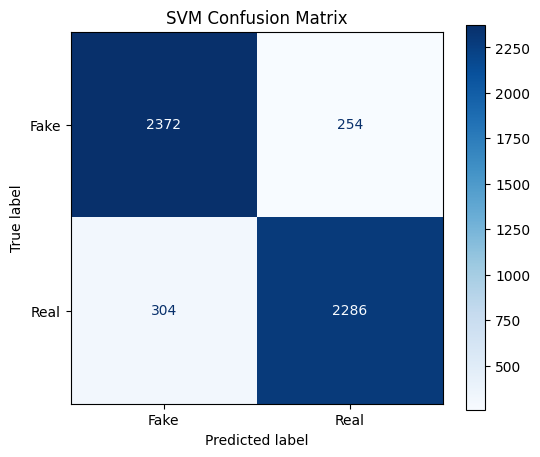

In [ ]:
# 2. Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, svm_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fake', 'Real'])
disp.plot(ax=ax, cmap=plt.cm.Blues)
plt.title('SVM Confusion Matrix')
plt.show()

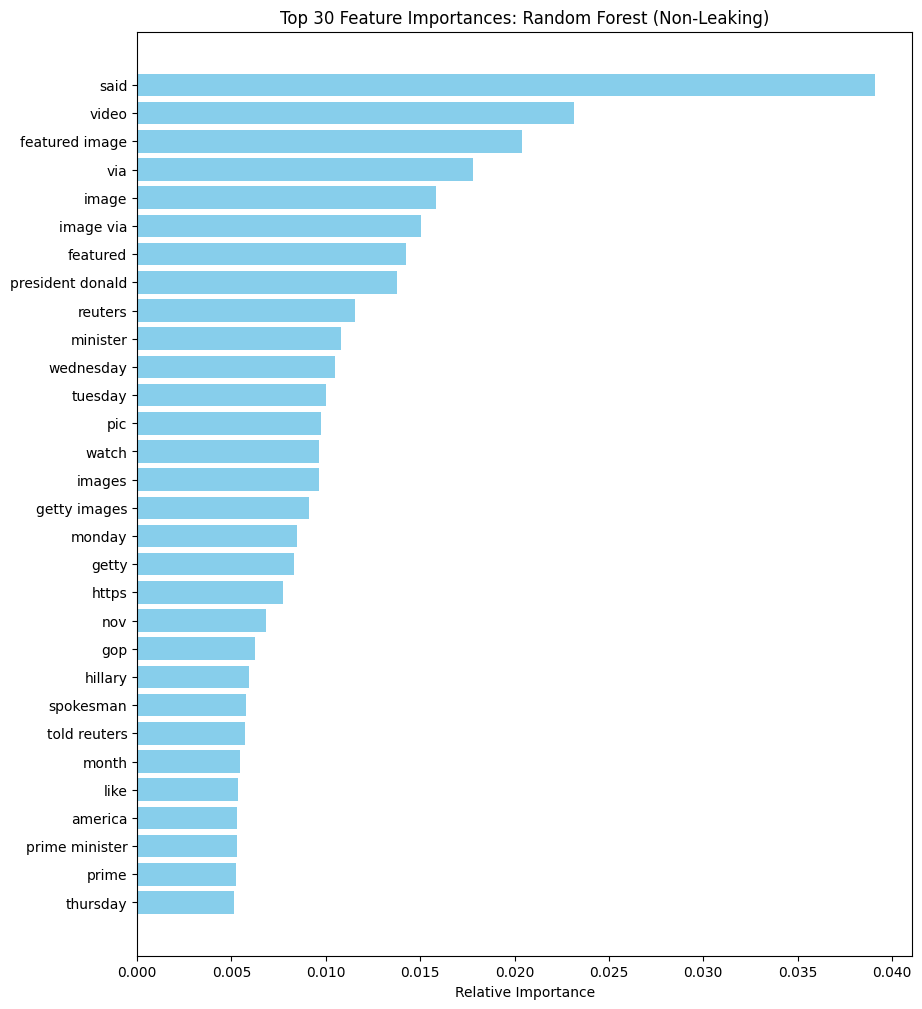

--- Top 10 Most Discriminative Words for Random Forest ---
said            : 0.0391
video           : 0.0231
featured image  : 0.0204
via             : 0.0178
image           : 0.0158
image via       : 0.0150
featured        : 0.0143
president donald : 0.0138
reuters         : 0.0115
minister        : 0.0108


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Extract Feature Importances from the Random Forest model
# Note: rf_word_m_fixed was trained on X_train_word_fixed (TF-IDF Word Features)
importances = rf_word_m_fixed.feature_importances_
feature_names = tfidf_word_fixed.get_feature_names_out()

# 2. Sort and Get Top 30 Features
indices = np.argsort(importances)[-30:]

plt.figure(figsize=(10, 12))
plt.title('Top 30 Feature Importances: Random Forest (Non-Leaking)')
plt.barh(range(len(indices)), importances[indices], color='skyblue', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

# 3. Print the top 10 features directly
print('--- Top 10 Most Discriminative Words for Random Forest ---')
top_10 = sorted(zip(importances, feature_names), reverse=True)[:10]
for weight, word in top_10:
    print(f'{word:<15} : {weight:.4f}')

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
import numpy as np

print('--- Building a Stacking Meta-Learner ---')

# 1. Tokenize Validation Set for BERT
# Using dataset_with_cleaned_text which is defined in the notebook
def tokenize_func(examples):
    return tokenizer(examples['text'], padding='max_length', truncation=True, max_length=512)

tokenized_val = dataset_with_cleaned_text['validation'].map(tokenize_func, batched=True)

# 2. Prepare 'Meta-Features' (Predictions on the Validation Set)
bert_val_results = trainer.predict(tokenized_val)
bert_p1_val = np.exp(bert_val_results.predictions) / (np.sum(np.exp(bert_val_results.predictions), axis=-1, keepdims=True) + 1e-10)
bert_p1_val = bert_p1_val[:, 1]

lrw_p1_val = lr_word_m_fixed.predict_proba(X_val_word_fixed)[:, 1]
svmc_scores_val = svm_char_m_fixed.decision_function(X_val_char_fixed)
svmc_p1_val = (svmc_scores_val - svmc_scores_val.min()) / (svmc_scores_val.max() - svmc_scores_val.min() + 1e-10)
rfw_p1_val = rf_word_m_fixed.predict_proba(X_val_word_fixed)[:, 1]
lre_p1_val = lr_embed_m_fixed.predict_proba(X_val_embed_fixed)[:, 1]

# Create the Meta-Feature Matrix
X_meta_train = np.column_stack([
    bert_p1_val, lrw_p1_val, svmc_p1_val, rfw_p1_val, lre_p1_val
])
y_meta_train = np.array(dataset_with_cleaned_text['validation']['label'])

# 3. Train the Meta-Learner
meta_model = LogisticRegression().fit(X_meta_train, y_meta_train)

# 4. Generate Final Predictions on the TEST set
# bert_p1_fixed, lrw_p1_fixed, etc. are already defined for the test set
X_meta_test = np.column_stack([
    bert_p1_fixed, lrw_p1_fixed, svmc_p1_fixed, rfw_p1_fixed, lre_p1_fixed
])
stacking_probs = meta_model.predict_proba(X_meta_test)[:, 1]
stacking_preds = (stacking_probs > 0.5).astype(int)

print('Stacking Ensemble Training Complete.')

--- Building a Stacking Meta-Learner ---


NameError: name 'dataset_with_cleaned_text' is not defined

In [ ]:
import pandas as pd

# Calculate final metrics for the Stacked Ensemble
y_test_final = np.array(dataset_with_cleaned_text['test']['label'])
stack_acc = accuracy_score(y_test_final, stacking_preds)
stack_auc = roc_auc_score(y_test_final, stacking_probs)

# Compare with individual models (using variables from previous cells)
comparison_data = {
    'Model': ['BERT', 'LR (Word)', 'SVM (Char)', 'Random Forest', 'LR (Embed)', 'STACKED ENSEMBLE'],
    'Accuracy': [
        accuracy_score(y_test_final, (bert_p1_fixed > 0.5).astype(int)),
        accuracy_score(y_test_final, (lrw_p1_fixed > 0.5).astype(int)),
        accuracy_score(y_test_final, (svmc_p1_fixed > 0.5).astype(int)),
        accuracy_score(y_test_final, (rfw_p1_fixed > 0.5).astype(int)),
        accuracy_score(y_test_final, (lre_p1_fixed > 0.5).astype(int)),
        stack_acc
    ],
    'AUC-ROC': [
        roc_auc_score(y_test_final, bert_p1_fixed),
        roc_auc_score(y_test_final, lrw_p1_fixed),
        roc_auc_score(y_test_final, svmc_p1_fixed),
        roc_auc_score(y_test_final, rfw_p1_fixed),
        roc_auc_score(y_test_final, lre_p1_fixed),
        stack_auc
    ]
}

comparison_df = pd.DataFrame(comparison_data).sort_values(by='Accuracy', ascending=False)
display(comparison_df.style.highlight_max(axis=0, color='lightgreen'))

print('\n--- Final Stacked Ensemble Report ---')
print(classification_report(y_test_final, stacking_preds, target_names=['Fake', 'Real']))

NameError: name 'stacking_preds' is not defined

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Prepare comparative stats to show the 'Reader' vs 'Shortcut' divide
model_probs = {
    'BERT (Deep Reader)': bert_p1_fixed,
    'LR (Word TF-IDF)': lrw_p1_fixed,
    'SVM (Char Shortcut)': svmc_p1_fixed,
    'RF (Structural Shortcut)': rfw_p1_fixed,
    'LR (Embeddings)': lre_p1_fixed
}

comparison_stats = []
y_true_arr = np.array(dataset_with_cleaned_text['test']['label'])

for name, probs in model_probs.items():
    preds = (probs > 0.5).astype(int)
    comparison_stats.append({
        'Model Type': name,
        'Precision (Avoids FPs)': precision_score(y_true_arr, preds),
        'Recall (Avoids FNs)': recall_score(y_true_arr, preds),
        'F1-Score': f1_score(y_true_arr, preds)
    })

performance_df = pd.DataFrame(comparison_stats)
print("--- Model Specialization Comparison ---")
print("High Precision = Very cautious 'Real' detector. High Recall = Catches almost all Real news.")
display(performance_df.sort_values('F1-Score', ascending=False).style.background_gradient(cmap='RdYlGn'))

--- Model Specialization Comparison ---
High Precision = Very cautious 'Real' detector. High Recall = Catches almost all Real news.


,Model Type,Precision (Avoids FPs),Recall (Avoids FNs),F1-Score
0,BERT (Deep Reader),0.889711,0.928185,0.908541
1,LR (Word TF-IDF),0.923680,0.864479,0.893099
3,RF (Structural Shortcut),0.961905,0.818919,0.884672
4,LR (Embeddings),0.854510,0.841313,0.847860
2,SVM (Char Shortcut),0.705315,0.988803,0.823340


--- Logistic Regression (Word TF-IDF) Performance ---
              precision    recall  f1-score   support

        Fake       0.87      0.93      0.90      2626
        Real       0.92      0.86      0.89      2590

    accuracy                           0.90      5216
   macro avg       0.90      0.90      0.90      5216
weighted avg       0.90      0.90      0.90      5216



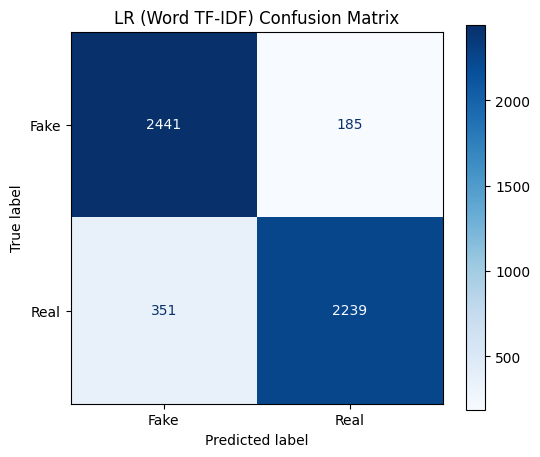

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# 1. Logistic Regression (Word TF-IDF)
preds_lrw = (lrw_p1_fixed > 0.5).astype(int)

print("--- Logistic Regression (Word TF-IDF) Performance ---")
print(classification_report(y_test_arr, preds_lrw, target_names=['Fake', 'Real']))

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test_arr, preds_lrw)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fake', 'Real'])
disp.plot(ax=ax, cmap=plt.cm.Blues)
plt.title('LR (Word TF-IDF) Confusion Matrix')
plt.show()

--- Logistic Regression (Embeddings) Performance ---
              precision    recall  f1-score   support

        Fake       0.85      0.86      0.85      2626
        Real       0.85      0.84      0.85      2590

    accuracy                           0.85      5216
   macro avg       0.85      0.85      0.85      5216
weighted avg       0.85      0.85      0.85      5216



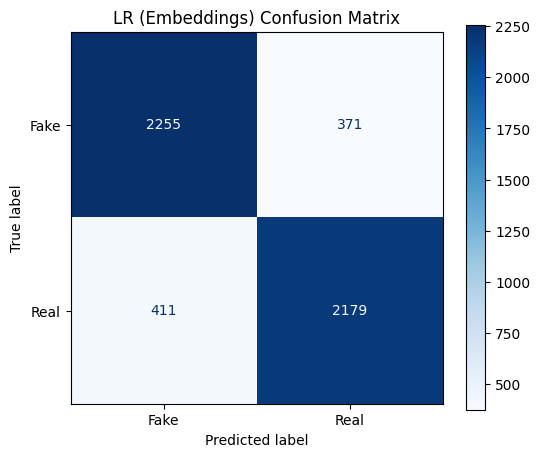

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# 2. Logistic Regression (Embeddings)
preds_lre = (lre_p1_fixed > 0.5).astype(int)

print("--- Logistic Regression (Embeddings) Performance ---")
print(classification_report(y_test_arr, preds_lre, target_names=['Fake', 'Real']))

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test_arr, preds_lre)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fake', 'Real'])
disp.plot(ax=ax, cmap=plt.cm.Blues)
plt.title('LR (Embeddings) Confusion Matrix')
plt.show()

--- Random Forest Performance ---
              precision    recall  f1-score   support

        Fake       0.84      0.97      0.90      2626
        Real       0.96      0.82      0.88      2590

    accuracy                           0.89      5216
   macro avg       0.90      0.89      0.89      5216
weighted avg       0.90      0.89      0.89      5216



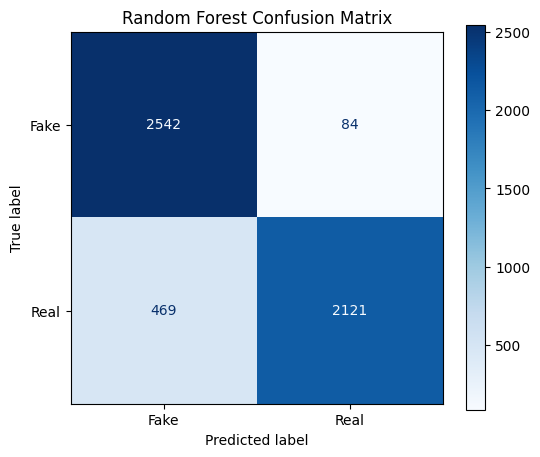

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# 3. Random Forest (Word TF-IDF)
preds_rf = (rfw_p1_fixed > 0.5).astype(int)

print("--- Random Forest Performance ---")
print(classification_report(y_test_arr, preds_rf, target_names=['Fake', 'Real']))

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test_arr, preds_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fake', 'Real'])
disp.plot(ax=ax, cmap=plt.cm.Blues)
plt.title('Random Forest Confusion Matrix')
plt.show()

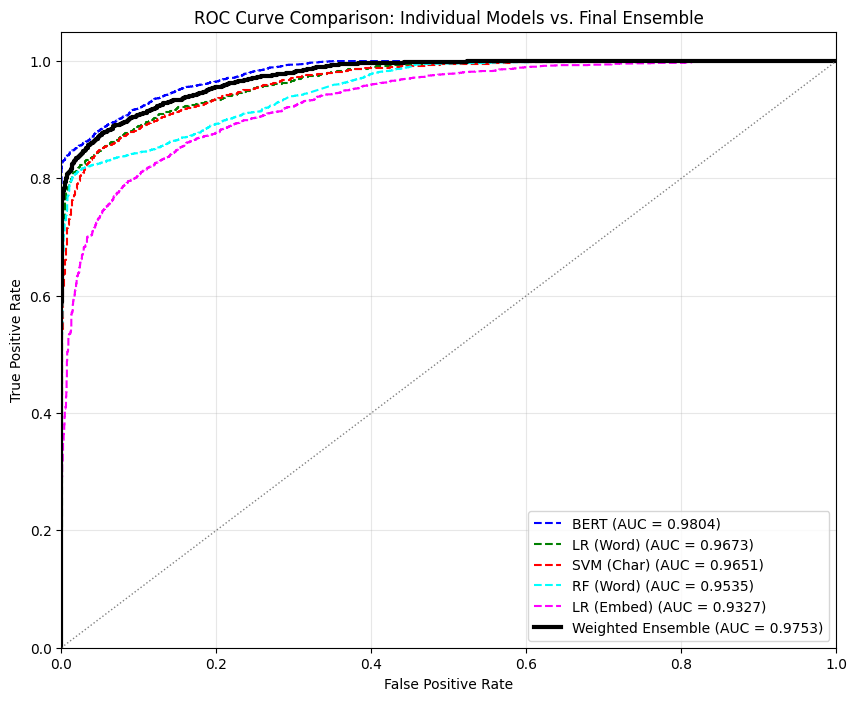

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# 4. AUC-ROC Comparison Curve
plt.figure(figsize=(10, 8))

model_probs = {
    'BERT': bert_p1_fixed,
    'LR (Word)': lrw_p1_fixed,
    'SVM (Char)': svmc_p1_fixed,
    'RF (Word)': rfw_p1_fixed,
    'LR (Embed)': lre_p1_fixed,
    'Weighted Ensemble': final_probs
}

colors = ['blue', 'green', 'red', 'cyan', 'magenta', 'black']
styles = ['--', '--', '--', '--', '--', '-']

for (name, probs), color, style in zip(model_probs.items(), colors, styles):
    fpr, tpr, _ = roc_curve(y_test_arr, probs)
    roc_auc = auc(fpr, tpr)
    lw = 3 if name == 'Weighted Ensemble' else 1.5
    plt.plot(fpr, tpr, color=color, lw=lw, linestyle=style, label=f'{name} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle=':')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: Individual Models vs. Final Ensemble')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()